In [7]:
from pathlib import Path

INPUT_ROOT = Path('/kaggle/input')

for dataset in INPUT_ROOT.iterdir():
    if dataset.is_dir():
        print("\nDataset:", dataset.name)

        for item in dataset.iterdir():
            print("  ", item.name)


Dataset: datasets
   vipoooool
   meerqamar


In [8]:
from pathlib import Path

root = Path("/kaggle/input/datasets/vipoooool")

print("Folders inside vipoooool:\n")

for item in root.iterdir():
    print(item.name, "(Folder)" if item.is_dir() else "(File)")

Folders inside vipoooool:

new-plant-diseases-dataset (Folder)


In [10]:
from pathlib import Path

NEW_PLANT_PATH = Path(
    "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"
)

print("New Plant Diseases Dataset:")

for item in NEW_PLANT_PATH.iterdir():
    print(item.name, "(Folder)" if item.is_dir() else "(File)")

New Plant Diseases Dataset:
New Plant Diseases Dataset(Augmented) (Folder)
new plant diseases dataset(augmented) (Folder)
test (Folder)


In [11]:
from pathlib import Path

root = Path(NEW_PLANT_PATH)

for folder in root.iterdir():
    if folder.is_dir():
        print(f"\n📁 {folder.name}")
        for subfolder in folder.iterdir():
            if subfolder.is_dir():
                print("   └──", subfolder.name)



📁 New Plant Diseases Dataset(Augmented)
   └── New Plant Diseases Dataset(Augmented)

📁 new plant diseases dataset(augmented)
   └── New Plant Diseases Dataset(Augmented)

📁 test
   └── test


In [12]:
from pathlib import Path

root = Path(NEW_PLANT_PATH)

for folder in root.rglob("*"):
    if folder.is_dir() and folder.name.lower() in ["train", "valid", "validation", "test"]:
        subfolders = [x.name for x in folder.iterdir() if x.is_dir()]
        print(f"\nPath: {folder}")
        print(f"Number of class folders: {len(subfolders)}")
        print("Classes:", subfolders[:10])


Path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test
Number of class folders: 1
Classes: ['test']

Path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test
Number of class folders: 0
Classes: []

Path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
Number of class folders: 38
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']

Path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid
Number of class folders: 38
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'App

In [17]:
from pathlib import Path

BASE = Path("/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset")

NEW_PLANT_TRAIN = (
    BASE / "new plant diseases dataset(augmented)"
    / "New Plant Diseases Dataset(Augmented)" / "train"
)

NEW_PLANT_VALID = (
    BASE / "new plant diseases dataset(augmented)"
    / "New Plant Diseases Dataset(Augmented)" / "valid"
)

for split_name, split_path in [
    ("Train", NEW_PLANT_TRAIN),
    ("Validation", NEW_PLANT_VALID)
]:
    print(f"\n{split_name} Dataset")

    total_images = 0

    for class_folder in sorted(split_path.iterdir()):
        if class_folder.is_dir():
            count = sum(
                1 for f in class_folder.iterdir()
                if f.is_file() and f.suffix.lower() in
                [".jpg", ".jpeg", ".png", ".bmp"]
            )
            total_images += count
            print(f"{class_folder.name}: {count}")

    print(f"Total {split_name} Images: {total_images}")


Train Dataset
Apple___Apple_scab: 2016
Apple___Black_rot: 1987
Apple___Cedar_apple_rust: 1760
Apple___healthy: 2008
Blueberry___healthy: 1816
Cherry_(including_sour)___Powdery_mildew: 1683
Cherry_(including_sour)___healthy: 1826
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 1642
Corn_(maize)___Common_rust_: 1907
Corn_(maize)___Northern_Leaf_Blight: 1908
Corn_(maize)___healthy: 1859
Grape___Black_rot: 1888
Grape___Esca_(Black_Measles): 1920
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1722
Grape___healthy: 1692
Orange___Haunglongbing_(Citrus_greening): 2010
Peach___Bacterial_spot: 1838
Peach___healthy: 1728
Pepper,_bell___Bacterial_spot: 1913
Pepper,_bell___healthy: 1988
Potato___Early_blight: 1939
Potato___Late_blight: 1939
Potato___healthy: 1824
Raspberry___healthy: 1781
Soybean___healthy: 2022
Squash___Powdery_mildew: 1736
Strawberry___Leaf_scorch: 1774
Strawberry___healthy: 1824
Tomato___Bacterial_spot: 1702
Tomato___Early_blight: 1920
Tomato___Late_blight: 1851
Tomato___Leaf_

In [18]:
from pathlib import Path

# ==========================================
# STEP 1: DATASET PATH CONFIGURATION
# ==========================================

BASE = Path("/kaggle/input/datasets")

# 1. New Plant Diseases
NEW_PLANT_ROOT = (
    BASE / "vipoooool" / "new-plant-diseases-dataset"
    / "new plant diseases dataset(augmented)"
    / "New Plant Diseases Dataset(Augmented)"
)

NEW_PLANT_TRAIN = NEW_PLANT_ROOT / "train"
NEW_PLANT_VALID = NEW_PLANT_ROOT / "valid"

# 2. PlantDoc
PLANTDOC_ROOT = BASE / "meerqamar" / "plantdoc"
PLANTDOC_TRAIN = PLANTDOC_ROOT / "train"
PLANTDOC_TEST = PLANTDOC_ROOT / "test"

# 3. Rice Leaf Disease
RICE_ROOT = BASE / "meerqamar" / "riceyleafdisease"

# Find the Original Images directory containing class folders
rice_candidates = []

for folder in RICE_ROOT.rglob("Original Images"):
    classes = [
        p for p in folder.iterdir()
        if p.is_dir() and any(
            f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
            for f in p.rglob("*") if f.is_file()
        )
    ]

    if classes:
        rice_candidates.append((len(classes), folder))

if not rice_candidates:
    raise FileNotFoundError("Rice Original Images folder not found!")

RICE_ORIGINAL = max(rice_candidates, key=lambda x: x[0])[1]

# ==========================================
# STEP 2: IMAGE COUNT FUNCTION
# ==========================================

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def audit_dataset(name, train_path, eval_path):
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    for split_name, path in [
        ("TRAIN", train_path),
        ("VALIDATION / TEST", eval_path)
    ]:
        if not path.exists():
            print(f"{split_name}: PATH NOT FOUND -> {path}")
            continue

        classes = sorted([p for p in path.iterdir() if p.is_dir()])
        total = 0

        print(f"\n{split_name}")
        print("Classes:", len(classes))

        for cls in classes:
            count = sum(
                1 for f in cls.rglob("*")
                if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
            )
            total += count

        print("Total images:", total)
        print("Path:", path)

        if classes:
            print("First 5 classes:", [c.name for c in classes[:5]])

    if train_path.exists() and eval_path.exists():
        train_classes = {p.name for p in train_path.iterdir() if p.is_dir()}
        eval_classes = {p.name for p in eval_path.iterdir() if p.is_dir()}

        print("\nShared classes:", len(train_classes & eval_classes))
        print("Train-only classes:", sorted(train_classes - eval_classes))
        print("Eval-only classes:", sorted(eval_classes - train_classes))


# ==========================================
# STEP 3: VERIFY ALL THREE DATASETS
# ==========================================

audit_dataset(
    "NEW PLANT DISEASES",
    NEW_PLANT_TRAIN,
    NEW_PLANT_VALID
)

audit_dataset(
    "PLANTDOC",
    PLANTDOC_TRAIN,
    PLANTDOC_TEST
)

print("\n" + "=" * 60)
print("RICE LEAF DISEASE")
print("=" * 60)
print("Original images path:", RICE_ORIGINAL)
print("Number of classes:", len([
    p for p in RICE_ORIGINAL.iterdir() if p.is_dir()
]))

rice_total = 0

for cls in sorted(RICE_ORIGINAL.iterdir()):
    if cls.is_dir():
        count = sum(
            1 for f in cls.rglob("*")
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        )
        rice_total += count
        print(f"{cls.name}: {count}")

print("Total original Rice images:", rice_total)

print("\nDATASET PATH CONFIGURATION COMPLETED!")


NEW PLANT DISEASES

TRAIN
Classes: 38
Total images: 70295
Path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']

VALIDATION / TEST
Classes: 38
Total images: 17572
Path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']

Shared classes: 38
Train-only classes: []
Eval-only classes: []

PLANTDOC

TRAIN
Classes: 28
Total images: 2308
Path: /kaggle/input/datasets/meerqamar/plantdoc/train
First 5 classes: ['Apple Scab Leaf', 'Apple leaf', 'Apple rust leaf', 'Bell_pepper leaf', 'Bell_pepper leaf spot']

VALIDATION / TEST
Classes: 27
Total images: 233
P

In [23]:

# ==========================================
# STEP 2: PYTORCH DATA PIPELINE
# ==========================================

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from pathlib import Path

# Reproducibility
SEED = 42
torch.manual_seed(SEED)

BATCH_SIZE = 32
NUM_WORKERS = 2

# ------------------------------------------
# 1. IMAGE TRANSFORMS
# ------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------
# 2. HELPER: CREATE DATALOADER
# ------------------------------------------

def make_loader(dataset, shuffle=False):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

# ------------------------------------------
# 3. NEW PLANT DISEASES
# ------------------------------------------

new_train = datasets.ImageFolder(
    NEW_PLANT_TRAIN,
    transform=train_transform
)

new_valid = datasets.ImageFolder(
    NEW_PLANT_VALID,
    transform=eval_transform
)

assert new_train.classes == new_valid.classes

new_train_loader = make_loader(new_train, shuffle=True)
new_valid_loader = make_loader(new_valid)

NEW_PLANT_CLASSES = new_train.classes

# ------------------------------------------
# 4. PLANTDOC
# ------------------------------------------

# First inspect original class names
plant_train_raw = datasets.ImageFolder(PLANTDOC_TRAIN)
plant_test_raw = datasets.ImageFolder(PLANTDOC_TEST)

shared_classes = sorted(
    set(plant_train_raw.classes) &
    set(plant_test_raw.classes)
)

print("PlantDoc shared classes:", len(shared_classes))

# Rebuild ImageFolder labels using only shared classes
def make_filtered_plantdoc(root, transform):
    ds = datasets.ImageFolder(root, transform=transform)

    new_class_to_idx = {
        name: idx for idx, name in enumerate(shared_classes)
    }

    filtered_samples = []

    for path, old_label in ds.samples:
        class_name = ds.classes[old_label]

        if class_name in new_class_to_idx:
            filtered_samples.append(
                (path, new_class_to_idx[class_name])
            )

    ds.classes = shared_classes
    ds.class_to_idx = new_class_to_idx
    ds.samples = filtered_samples
    ds.imgs = filtered_samples
    ds.targets = [label for _, label in filtered_samples]

    return ds

# Separate datasets for training and evaluation transforms
plant_train_ds = make_filtered_plantdoc(
    PLANTDOC_TRAIN, train_transform
)

plant_train_eval_ds = make_filtered_plantdoc(
    PLANTDOC_TRAIN, eval_transform
)

plant_test_ds = make_filtered_plantdoc(
    PLANTDOC_TEST, eval_transform
)

# Split training data into train and validation
plant_targets = plant_train_ds.targets
plant_indices = list(range(len(plant_targets)))

plant_train_idx, plant_valid_idx = train_test_split(
    plant_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=plant_targets
)

plant_train_loader = make_loader(
    Subset(plant_train_ds, plant_train_idx),
    shuffle=True
)

plant_valid_loader = make_loader(
    Subset(plant_train_eval_ds, plant_valid_idx)
)

# Official test is kept separate for final evaluation
plant_test_loader = make_loader(plant_test_ds)

PLANTDOC_CLASSES = shared_classes

# ------------------------------------------
# 5. RICE LEAF DISEASE
# ------------------------------------------

rice_train_ds = datasets.ImageFolder(
    RICE_ORIGINAL,
    transform=train_transform
)

rice_eval_ds = datasets.ImageFolder(
    RICE_ORIGINAL,
    transform=eval_transform
)

rice_targets = rice_train_ds.targets
rice_indices = list(range(len(rice_targets)))

rice_train_idx, rice_valid_idx = train_test_split(
    rice_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=rice_targets
)

rice_train_loader = make_loader(
    Subset(rice_train_ds, rice_train_idx),
    shuffle=True
)

rice_valid_loader = make_loader(
    Subset(rice_eval_ds, rice_valid_idx)
)

RICE_CLASSES = rice_train_ds.classes

# ------------------------------------------
# 6. FINAL PIPELINE SUMMARY
# ------------------------------------------

print("\n========== DATA PIPELINE SUMMARY ==========")

print("\nNew Plant Diseases")
print("Classes:", len(NEW_PLANT_CLASSES))
print("Train:", len(new_train))
print("Validation:", len(new_valid))

print("\nPlantDoc")
print("Classes:", len(PLANTDOC_CLASSES))
print("Train:", len(plant_train_idx))
print("Validation:", len(plant_valid_idx))
print("Official Test:", len(plant_test_ds))

print("\nRice Leaf Disease")
print("Classes:", len(RICE_CLASSES))
print("Train:", len(rice_train_idx))
print("Validation:", len(rice_valid_idx))

print("\nGPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

print("\nDATA PIPELINE READY!")


PlantDoc shared classes: 27

========== DATA PIPELINE SUMMARY ==========

New Plant Diseases
Classes: 38
Train: 70295
Validation: 17572

PlantDoc
Classes: 27
Train: 1844
Validation: 462
Official Test: 233

Rice Leaf Disease
Classes: 8
Train: 1360
Validation: 341

GPU: Tesla T4

DATA PIPELINE READY!


In [27]:

# ==========================================
# FIX: DATALOADER WORKER ISSUE
# ==========================================

NUM_WORKERS = 0
BATCH_SIZE = 32

def make_loader(dataset, shuffle=False):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

# Recreate all DataLoaders

new_train_loader = make_loader(new_train, shuffle=True)
new_valid_loader = make_loader(new_valid)

plant_train_loader = make_loader(
    Subset(plant_train_ds, plant_train_idx),
    shuffle=True
)

plant_valid_loader = make_loader(
    Subset(plant_train_eval_ds, plant_valid_idx)
)

plant_test_loader = make_loader(plant_test_ds)

rice_train_loader = make_loader(
    Subset(rice_train_ds, rice_train_idx),
    shuffle=True
)

rice_valid_loader = make_loader(
    Subset(rice_eval_ds, rice_valid_idx)
)

print("All DataLoaders recreated!")
print("NUM_WORKERS:", NUM_WORKERS)


All DataLoaders recreated!
NUM_WORKERS: 0


In [28]:
for name, loader in [
    ("New Plant", new_train_loader),
    ("PlantDoc", plant_train_loader),
    ("Rice", rice_train_loader)
]:
    images, labels = next(iter(loader))

    print(f"\n{name}")
    print("Images:", images.shape)
    print("Labels:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label range:", labels.min().item(), "-", labels.max().item())


New Plant
Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Image dtype: torch.float32
Label range: 2 - 36

PlantDoc
Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Image dtype: torch.float32
Label range: 1 - 26

Rice
Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Image dtype: torch.float32
Label range: 0 - 7


In [29]:

import torch
import torch.nn as nn

from torchvision.models import (
    alexnet,
    AlexNet_Weights,
    efficientnet_b0,
    EfficientNet_B0_Weights
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --------------------------------
# 1. AlexNet
# --------------------------------

def build_alexnet(num_classes, pretrained=True):

    weights = AlexNet_Weights.DEFAULT if pretrained else None

    model = alexnet(weights=weights)

    # Replace final classification layer
    input_features = model.classifier[6].in_features

    model.classifier[6] = nn.Linear(
        input_features,
        num_classes
    )

    return model


# --------------------------------
# 2. EfficientNet-B0
# --------------------------------

def build_efficientnet(num_classes, pretrained=True):

    weights = (
        EfficientNet_B0_Weights.DEFAULT
        if pretrained else None
    )

    model = efficientnet_b0(weights=weights)

    # Replace final classification layer
    input_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        input_features,
        num_classes
    )

    return model


# --------------------------------
# 3. Model information
# --------------------------------

def show_model_info(model, name):

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(f"\n{name}")
    print("Total parameters:", f"{total_params:,}")
    print("Trainable parameters:", f"{trainable_params:,}")


print("Device:", device)
print("Model building functions ready!")


Device: cuda
Model building functions ready!


In [32]:
import torch
import importlib
import sys

# Explicitly load PyTorch internal utilities
torch_utils = importlib.import_module("torch._utils")

# Restore module reference
torch._utils = torch_utils

print("Torch version:", torch.__version__)
print("Internal utils available:", hasattr(torch, "_utils"))
print("Element size function:", torch._utils._element_size)

Torch version: 2.11.0+cu130
Internal utils available: True
Element size function: <function _element_size at 0x795bd4594e00>


In [1]:
import torch
import sys
import importlib

print("PyTorch version:", torch.__version__)
print("Torch location:", torch.__file__)

print("Has dtype:", hasattr(torch, "dtype"))
print("Has _utils:", hasattr(torch, "_utils"))

print("CUDA available:", torch.cuda.is_available())

# Internal utility module
torch_utils = importlib.import_module("torch._utils")
torch._utils = torch_utils

print("Element size:", torch._utils._element_size)
print("Torch dtype:", torch.dtype)

PyTorch version: 2.11.0+cu130
Torch location: /usr/local/lib/python3.13/dist-packages/torch/__init__.py
Has dtype: True
Has _utils: True
CUDA available: True
Element size: <function _element_size at 0x7b2f32b709a0>
Torch dtype: <class 'torch.dtype'>


In [3]:
from torchvision import datasets, transforms

NEW_PLANT_TRAIN = (
    "/kaggle/input/datasets/vipoooool/"
    "new-plant-diseases-dataset/"
    "new plant diseases dataset(augmented)/"
    "New Plant Diseases Dataset(Augmented)/train"
)

NEW_PLANT_VALID = (
    "/kaggle/input/datasets/vipoooool/"
    "new-plant-diseases-dataset/"
    "new plant diseases dataset(augmented)/"
    "New Plant Diseases Dataset(Augmented)/valid"
)

new_train = datasets.ImageFolder(NEW_PLANT_TRAIN)
new_valid = datasets.ImageFolder(NEW_PLANT_VALID)

NEW_PLANT_CLASSES = new_train.classes

print("Number of classes:", len(NEW_PLANT_CLASSES))
print("Training images:", len(new_train))
print("Validation images:", len(new_valid))

Number of classes: 38
Training images: 70295
Validation images: 17572


In [7]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [8]:
model = model.to(device)
model.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output = model(dummy)

print("AlexNet loaded successfully!")
print("Output shape:", output.shape)
print("Device:", next(model.parameters()).device)

AlexNet loaded successfully!
Output shape: torch.Size([2, 38])
Device: cuda:0


In [10]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import torch.nn as nn

# Load pretrained EfficientNet-B0
model_eff = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Replace final classification layer
model_eff.classifier[1] = nn.Linear(
    model_eff.classifier[1].in_features,
    len(NEW_PLANT_CLASSES)
)

model_eff = model_eff.to(device)
model_eff.eval()

# Forward pass test
with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output_eff = model_eff(dummy)

print("EfficientNet-B0 loaded successfully!")
print("Output shape:", output_eff.shape)
print("Device:", next(model_eff.parameters()).device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 220MB/s]


EfficientNet-B0 loaded successfully!
Output shape: torch.Size([2, 38])
Device: cuda:0


In [2]:

NEW_PLANT_TRAIN = (
    "/kaggle/input/datasets/vipoooool/"
    "new-plant-diseases-dataset/"
    "new plant diseases dataset(augmented)/"
    "New Plant Diseases Dataset(Augmented)/train"
)

NEW_PLANT_VALID = (
    "/kaggle/input/datasets/vipoooool/"
    "new-plant-diseases-dataset/"
    "new plant diseases dataset(augmented)/"
    "New Plant Diseases Dataset(Augmented)/valid"
)

import os

print("Train path exists:", os.path.exists(NEW_PLANT_TRAIN))
print("Validation path exists:", os.path.exists(NEW_PLANT_VALID))


Train path exists: True
Validation path exists: True


In [3]:

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Configuration
BATCH_SIZE = 32
NUM_WORKERS = 0

# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation transformations
valid_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load datasets
new_train = datasets.ImageFolder(
    NEW_PLANT_TRAIN,
    transform=train_transform
)

new_valid = datasets.ImageFolder(
    NEW_PLANT_VALID,
    transform=valid_transform
)

# Create DataLoaders
new_train_loader = DataLoader(
    new_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

new_valid_loader = DataLoader(
    new_valid,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(new_train))
print("Validation images:", len(new_valid))
print("Number of classes:", len(new_train.classes))
print("Training batches:", len(new_train_loader))
print("Validation batches:", len(new_valid_loader))


Training images: 70295
Validation images: 17572
Number of classes: 38
Training batches: 2197
Validation batches: 550


In [4]:

images, labels = next(iter(new_train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image data type:", images.dtype)
print("Minimum label:", labels.min().item())
print("Maximum label:", labels.max().item())


Image batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image data type: torch.float32
Minimum label: 1
Maximum label: 34


In [9]:
from torchvision import datasets

new_train = datasets.ImageFolder(NEW_PLANT_TRAIN)

NEW_PLANT_CLASSES = new_train.classes
NUM_CLASSES = len(NEW_PLANT_CLASSES)

print("Number of classes:", NUM_CLASSES)
print("First 5 classes:", NEW_PLANT_CLASSES[:5])

Number of classes: 38
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [10]:
import torch
import torch.nn as nn
from torchvision.models import alexnet, AlexNet_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = alexnet(weights=AlexNet_Weights.DEFAULT)

model.classifier[6] = nn.Linear(
    model.classifier[6].in_features,
    NUM_CLASSES
)

model = model.to(device)

print("AlexNet ready!")
print("Classes:", NUM_CLASSES)
print("Device:", device)

AlexNet ready!
Classes: 38
Device: cuda


In [11]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

EPOCHS = 10

print("Training configuration ready!")

Training configuration ready!


In [14]:

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions created successfully!")


Training and validation functions created successfully!


In [15]:
print("Training function:", train_one_epoch)
print("Validation function:", validate_one_epoch)

Training function: <function train_one_epoch at 0x7ebdac14ee80>
Validation function: <function validate_one_epoch at 0x7ebdac14f420>


In [16]:

import copy
import time

EPOCHS = 10
best_val_accuracy = 0.0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    train_loss, train_acc = train_one_epoch(
        model,
        new_train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_acc = validate_one_epoch(
        model,
        new_valid_loader,
        criterion,
        device
    )

    # Store results
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    # Save best model
    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc
        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_weights,
            "/kaggle/working/best_alexnet_newplant.pth"
        )

    elapsed = time.time() - start_time

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Time: {elapsed:.2f} seconds")

print("\nAlexNet Training Completed!")
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")



Epoch [1/10]
Train Loss: 0.4861
Train Accuracy: 84.94%
Validation Loss: 0.1388
Validation Accuracy: 95.50%
Time: 888.36 seconds

Epoch [2/10]
Train Loss: 0.2473
Train Accuracy: 92.11%
Validation Loss: 0.1335
Validation Accuracy: 95.55%
Time: 363.08 seconds

Epoch [3/10]
Train Loss: 0.2060
Train Accuracy: 93.41%
Validation Loss: 0.1082
Validation Accuracy: 96.70%
Time: 364.76 seconds

Epoch [4/10]
Train Loss: 0.1846
Train Accuracy: 94.11%
Validation Loss: 0.0602
Validation Accuracy: 97.90%
Time: 362.27 seconds

Epoch [5/10]
Train Loss: 0.1679
Train Accuracy: 94.82%
Validation Loss: 0.0686
Validation Accuracy: 97.67%
Time: 361.42 seconds

Epoch [6/10]
Train Loss: 0.1555
Train Accuracy: 95.03%
Validation Loss: 0.0545
Validation Accuracy: 98.11%
Time: 362.37 seconds

Epoch [7/10]
Train Loss: 0.1440
Train Accuracy: 95.42%
Validation Loss: 0.1000
Validation Accuracy: 97.00%
Time: 395.21 seconds

Epoch [8/10]
Train Loss: 0.1379
Train Accuracy: 95.55%
Validation Loss: 0.0605
Validation Accura

In [17]:
import torch

checkpoint_path = "/kaggle/working/best_alexnet_newplant.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

model = model.to(device)
model.eval()

print("Best AlexNet checkpoint loaded!")
print("Best Validation Accuracy:", best_val_accuracy)

Best AlexNet checkpoint loaded!
Best Validation Accuracy: 98.69679034828135


===== ALEXNET EVALUATION =====
Accuracy:  98.70%
Precision: 98.71%
Recall:    98.70%
F1-Score:  98.68%

===== CLASSIFICATION REPORT =====
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9940    0.9901    0.9920       504
                                 Apple___Black_rot     0.9980    0.9940    0.9960       497
                          Apple___Cedar_apple_rust     1.0000    0.9932    0.9966       440
                                   Apple___healthy     0.9940    0.9960    0.9950       502
                               Blueberry___healthy     0.9848    1.0000    0.9923       454
          Cherry_(including_sour)___Powdery_mildew     0.9976    0.9952    0.9964       421
                 Cherry_(including_sour)___healthy     0.9978    0.9868    0.9923       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8925    0.9927    0.9400       410
                       Corn_(maiz

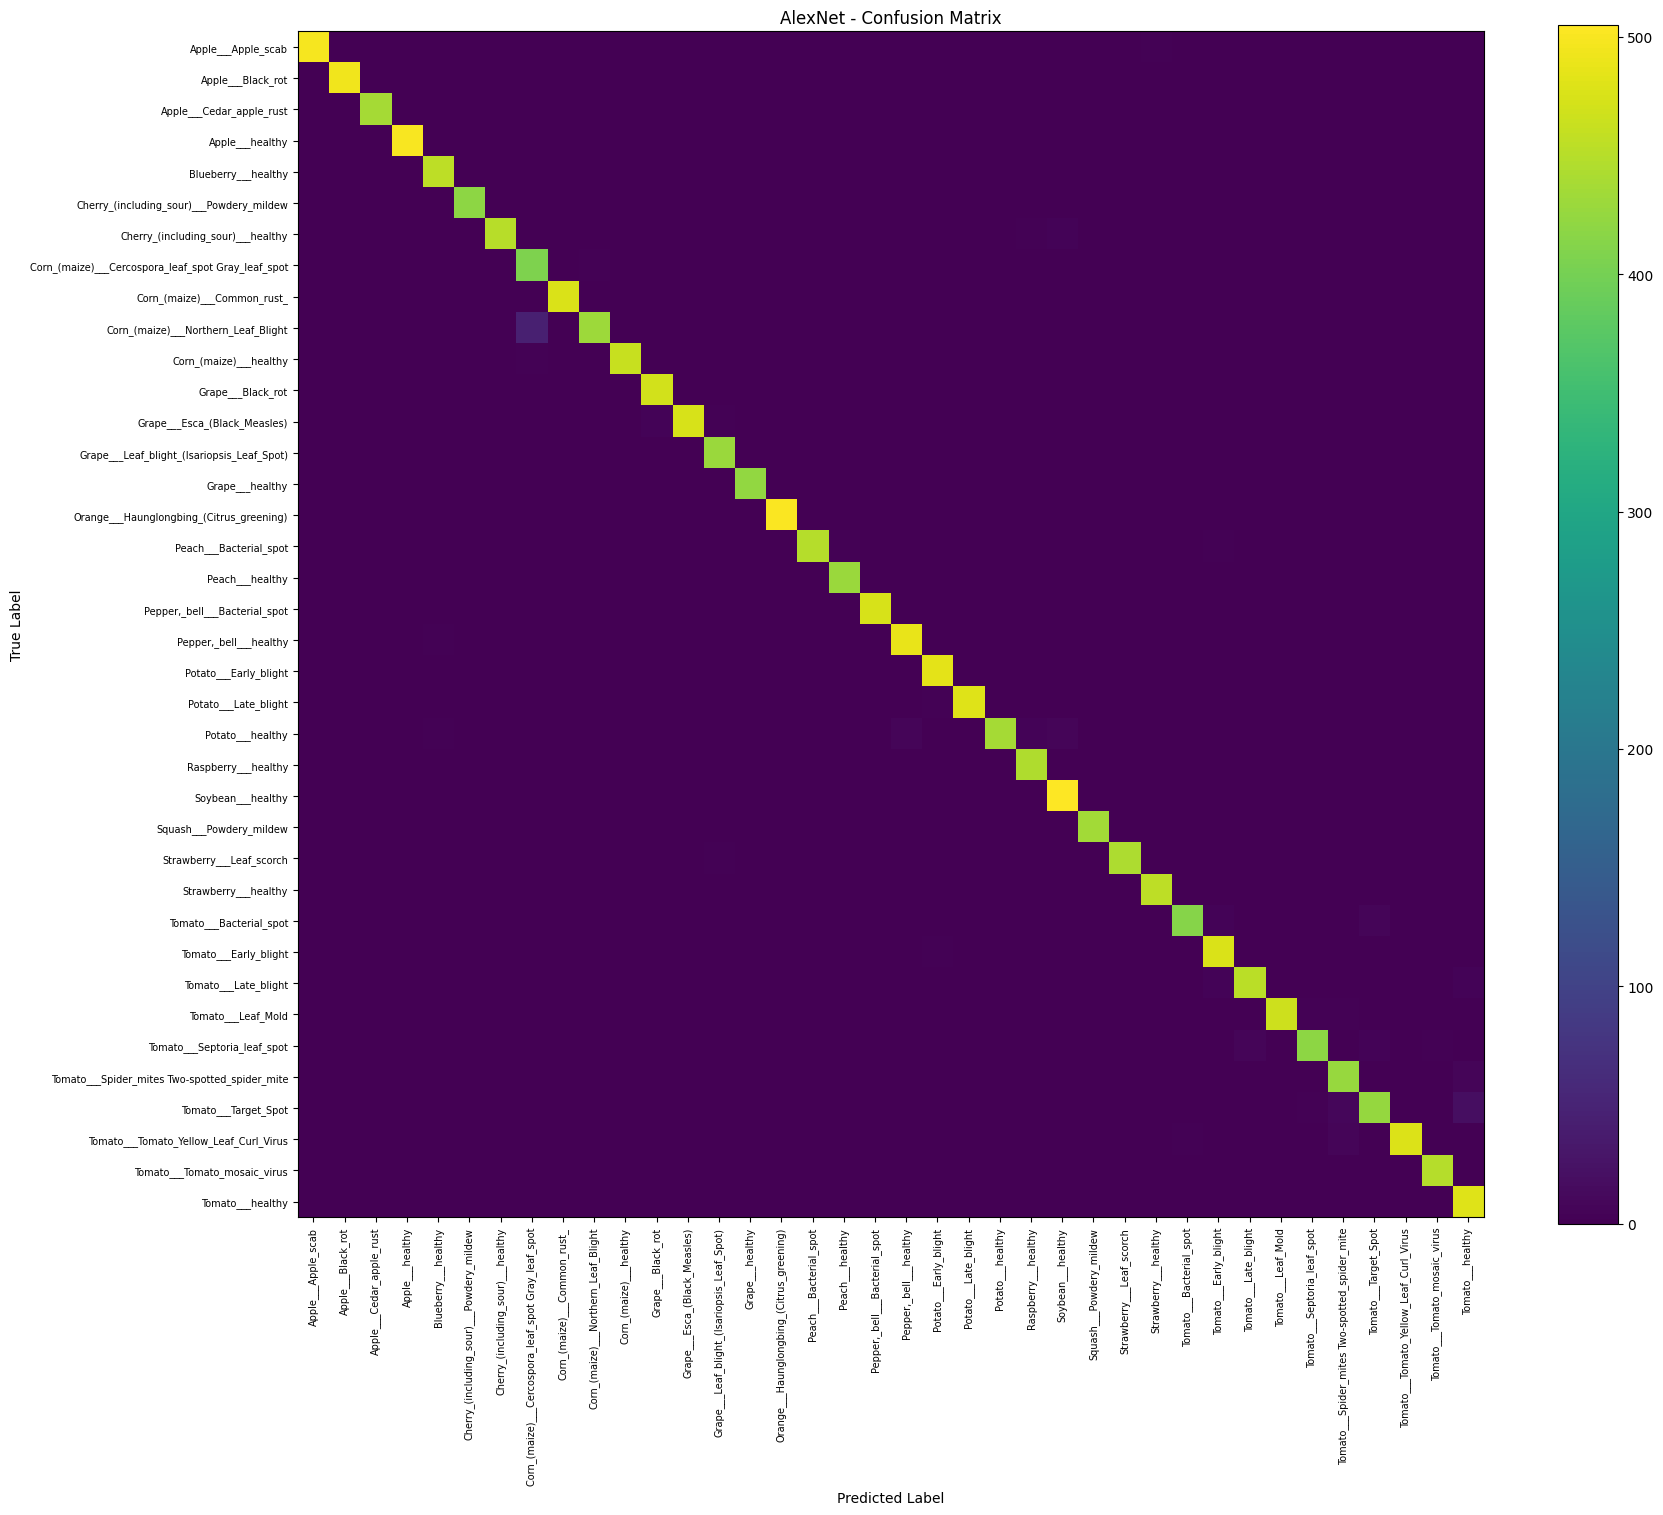

In [18]:

import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Best model evaluation mode
model.eval()

all_labels = []
all_predictions = []

# Generate predictions
with torch.no_grad():

    for images, labels in new_valid_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels, all_predictions, average="macro"
)

recall = recall_score(
    all_labels, all_predictions, average="macro"
)

f1 = f1_score(
    all_labels, all_predictions, average="macro"
)

print("===== ALEXNET EVALUATION =====")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

# Detailed class-wise report
print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=NEW_PLANT_CLASSES,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(18, 15))
plt.imshow(cm, interpolation="nearest")
plt.title("AlexNet - Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(NEW_PLANT_CLASSES)),
    NEW_PLANT_CLASSES,
    rotation=90,
    fontsize=7
)

plt.yticks(
    np.arange(len(NEW_PLANT_CLASSES)),
    NEW_PLANT_CLASSES,
    fontsize=7
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


In [19]:

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

# Load pretrained EfficientNet-B0
model_eff = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Replace final classifier
model_eff.classifier[1] = nn.Linear(
    model_eff.classifier[1].in_features,
    NUM_CLASSES
)

model_eff = model_eff.to(device)

# Loss and optimizer
criterion_eff = nn.CrossEntropyLoss()

optimizer_eff = optim.Adam(
    model_eff.parameters(),
    lr=0.0001
)

model_eff.eval()

# Test forward pass
with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output = model_eff(dummy)

print("EfficientNet-B0 ready!")
print("Output shape:", output.shape)
print("Device:", next(model_eff.parameters()).device)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


EfficientNet-B0 ready!
Output shape: torch.Size([2, 38])
Device: cuda:0


In [20]:

import copy
import time

EPOCHS = 10
best_eff_accuracy = 0.0

history_eff = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_eff_weights = copy.deepcopy(model_eff.state_dict())

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    train_loss, train_acc = train_one_epoch(
        model_eff,
        new_train_loader,
        criterion_eff,
        optimizer_eff,
        device
    )

    # Validation
    val_loss, val_acc = validate_one_epoch(
        model_eff,
        new_valid_loader,
        criterion_eff,
        device
    )

    # Store history
    history_eff["train_loss"].append(train_loss)
    history_eff["train_accuracy"].append(train_acc)
    history_eff["val_loss"].append(val_loss)
    history_eff["val_accuracy"].append(val_acc)

    # Save best checkpoint
    if val_acc > best_eff_accuracy:

        best_eff_accuracy = val_acc
        best_eff_weights = copy.deepcopy(model_eff.state_dict())

        torch.save(
            best_eff_weights,
            "/kaggle/working/best_efficientnet_newplant.pth"
        )

    elapsed = time.time() - start_time

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Time: {elapsed:.2f} seconds")

print("\nEfficientNet-B0 Training Completed!")
print(f"Best Validation Accuracy: {best_eff_accuracy:.2f}%")



Epoch [1/10]
Train Loss: 0.4651
Train Accuracy: 88.93%
Validation Loss: 0.0472
Validation Accuracy: 98.53%
Time: 667.45 seconds

Epoch [2/10]
Train Loss: 0.1208
Train Accuracy: 96.28%
Validation Loss: 0.0264
Validation Accuracy: 99.17%
Time: 674.67 seconds

Epoch [3/10]
Train Loss: 0.0888
Train Accuracy: 97.35%
Validation Loss: 0.0185
Validation Accuracy: 99.36%
Time: 663.09 seconds

Epoch [4/10]
Train Loss: 0.0763
Train Accuracy: 97.64%
Validation Loss: 0.0143
Validation Accuracy: 99.54%
Time: 672.92 seconds

Epoch [5/10]
Train Loss: 0.0661
Train Accuracy: 97.96%
Validation Loss: 0.0252
Validation Accuracy: 99.20%
Time: 663.12 seconds

Epoch [6/10]
Train Loss: 0.0573
Train Accuracy: 98.18%
Validation Loss: 0.0177
Validation Accuracy: 99.49%
Time: 676.68 seconds

Epoch [7/10]
Train Loss: 0.0527
Train Accuracy: 98.33%
Validation Loss: 0.0121
Validation Accuracy: 99.66%
Time: 677.43 seconds

Epoch [8/10]
Train Loss: 0.0495
Train Accuracy: 98.42%
Validation Loss: 0.0121
Validation Accura

In [22]:
model_eff.load_state_dict(
    torch.load(
        "/kaggle/working/best_efficientnet_newplant.pth",
        map_location=device,
        weights_only=True
    )
)

model_eff = model_eff.to(device)
model_eff.eval()

print("Best EfficientNet-B0 checkpoint loaded!")
print("Best Validation Accuracy:", best_eff_accuracy)

Best EfficientNet-B0 checkpoint loaded!
Best Validation Accuracy: 99.74391076712952


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model_eff.eval()

all_labels_eff = []
all_preds_eff = []

with torch.no_grad():
    for images, labels in new_valid_loader:

        images = images.to(device)

        outputs = model_eff(images)
        _, predicted = torch.max(outputs, 1)

        all_labels_eff.extend(labels.numpy())
        all_preds_eff.extend(predicted.cpu().numpy())

# Calculate metrics
accuracy_eff = accuracy_score(
    all_labels_eff, all_preds_eff
)

precision_eff = precision_score(
    all_labels_eff, all_preds_eff,
    average="macro"
)

recall_eff = recall_score(
    all_labels_eff, all_preds_eff,
    average="macro"
)

f1_eff = f1_score(
    all_labels_eff, all_preds_eff,
    average="macro"
)

print("EfficientNet-B0 Evaluation Results")
print("=" * 45)

print(f"Accuracy:  {accuracy_eff * 100:.2f}%")
print(f"Precision: {precision_eff * 100:.2f}%")
print(f"Recall:    {recall_eff * 100:.2f}%")
print(f"F1-Score:  {f1_eff * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels_eff,
    all_preds_eff,
    target_names=NEW_PLANT_CLASSES,
    digits=4
))

EfficientNet-B0 Evaluation Results
Accuracy:  99.74%
Precision: 99.74%
Recall:    99.74%
F1-Score:  99.74%

Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    1.0000    1.0000       504
                                 Apple___Black_rot     0.9960    1.0000    0.9980       497
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000       440
                                   Apple___healthy     1.0000    0.9980    0.9990       502
                               Blueberry___healthy     1.0000    1.0000    1.0000       454
          Cherry_(including_sour)___Powdery_mildew     1.0000    1.0000    1.0000       421
                 Cherry_(including_sour)___healthy     1.0000    0.9978    0.9989       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9760    0.9927    0.9843       410
                       Corn_(maize)___C

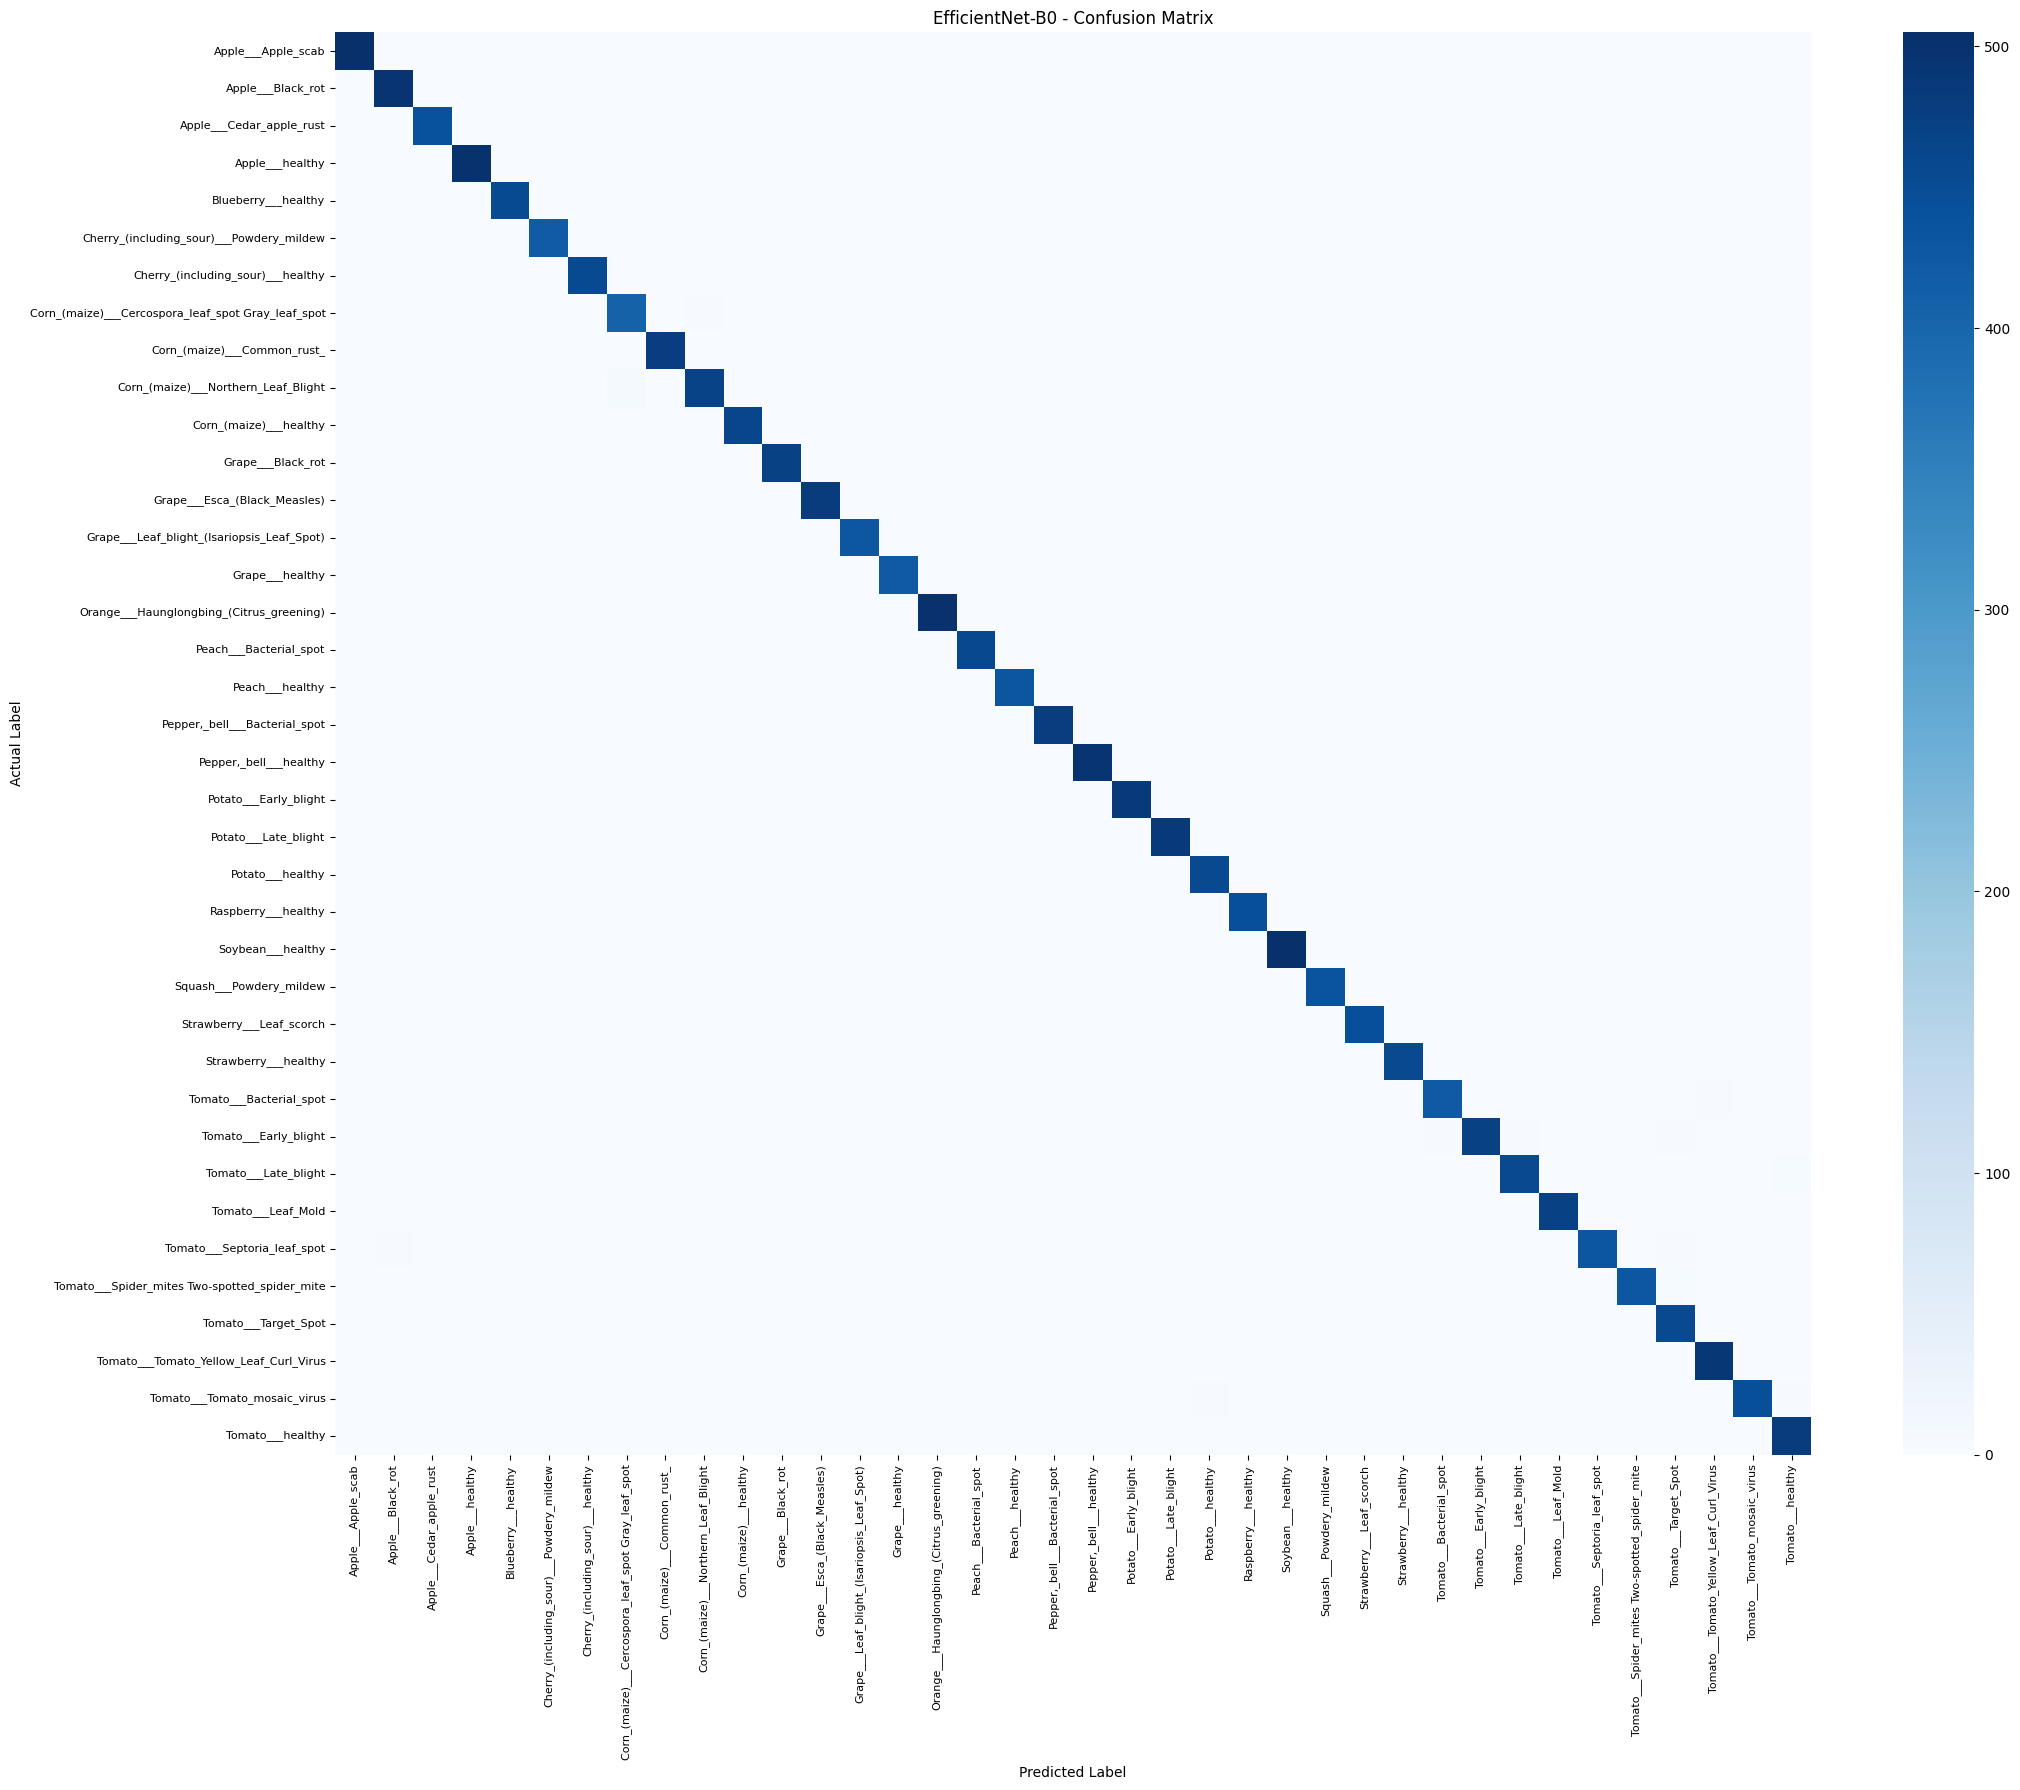

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_eff = confusion_matrix(
    all_labels_eff,
    all_preds_eff
)

plt.figure(figsize=(22, 18))

sns.heatmap(
    cm_eff,
    cmap="Blues",
    xticklabels=NEW_PLANT_CLASSES,
    yticklabels=NEW_PLANT_CLASSES
)

plt.title("EfficientNet-B0 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

### EfficientNet-B0 Confusion Matrix Analysis

The confusion matrix of EfficientNet-B0 demonstrates excellent classification performance on the New Plant Diseases validation dataset. The majority of predictions are concentrated along the main diagonal, indicating that the model correctly classified most images across the 38 disease and healthy plant categories. Very few misclassifications are observed outside the diagonal. These results are consistent with the model's overall accuracy of 99.74% and macro F1-score of 99.74%. The findings indicate strong classification performance on the validation dataset.

**Plantdoc Dataset**

In [25]:
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from PIL import Image

# Dataset paths
PLANTDOC_ROOT = Path(
    "/kaggle/input/datasets/meerqamar/plantdoc"
)

PLANTDOC_TRAIN = PLANTDOC_ROOT / "train"
PLANTDOC_TEST = PLANTDOC_ROOT / "test"

# Transforms
plant_train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

plant_valid_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Read original training dataset
plant_raw = datasets.ImageFolder(PLANTDOC_TRAIN)

# Read official test dataset
plant_test_raw = datasets.ImageFolder(PLANTDOC_TEST)

# Find common classes
PLANTDOC_CLASSES = sorted(
    set(plant_raw.classes) & set(plant_test_raw.classes)
)

PLANTDOC_CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(PLANTDOC_CLASSES)
}

NUM_PLANTDOC_CLASSES = len(PLANTDOC_CLASSES)

# Keep only shared classes
plant_samples = []

for image_path, old_label in plant_raw.samples:
    class_name = plant_raw.classes[old_label]

    if class_name in PLANTDOC_CLASS_TO_IDX:
        new_label = PLANTDOC_CLASS_TO_IDX[class_name]
        plant_samples.append((image_path, new_label))

# Stratified split
plant_labels = [label for _, label in plant_samples]

plant_train_samples, plant_valid_samples = train_test_split(
    plant_samples,
    test_size=0.20,
    random_state=42,
    stratify=plant_labels
)

# Custom dataset
class PlantDocDataset(Dataset):

    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Create datasets
plant_train_dataset = PlantDocDataset(
    plant_train_samples,
    transform=plant_train_transform
)

plant_valid_dataset = PlantDocDataset(
    plant_valid_samples,
    transform=plant_valid_transform
)

# Data loaders
plant_train_loader = DataLoader(
    plant_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

plant_valid_loader = DataLoader(
    plant_valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Summary
print("PLANTDOC DATASET READY")
print("=" * 40)

print("Number of Classes:", NUM_PLANTDOC_CLASSES)
print("Training Images:", len(plant_train_dataset))
print("Validation Images:", len(plant_valid_dataset))
print("Official Test Images:", len(plant_test_raw))

print("\nClasses:")
for i, class_name in enumerate(PLANTDOC_CLASSES):
    print(i, class_name)

# Test one batch
images, labels = next(iter(plant_train_loader))

print("\nBatch Image Shape:", images.shape)
print("Batch Label Shape:", labels.shape)
print("Number of Model Classes:", NUM_PLANTDOC_CLASSES)

PLANTDOC DATASET READY
Number of Classes: 27
Training Images: 1844
Validation Images: 462
Official Test Images: 233

Classes:
0 Apple Scab Leaf
1 Apple leaf
2 Apple rust leaf
3 Bell_pepper leaf
4 Bell_pepper leaf spot
5 Blueberry leaf
6 Cherry leaf
7 Corn Gray leaf spot
8 Corn leaf blight
9 Corn rust leaf
10 Peach leaf
11 Potato leaf early blight
12 Potato leaf late blight
13 Raspberry leaf
14 Soyabean leaf
15 Squash Powdery mildew leaf
16 Strawberry leaf
17 Tomato Early blight leaf
18 Tomato Septoria leaf spot
19 Tomato leaf
20 Tomato leaf bacterial spot
21 Tomato leaf late blight
22 Tomato leaf mosaic virus
23 Tomato leaf yellow virus
24 Tomato mold leaf
25 grape leaf
26 grape leaf black rot

Batch Image Shape: torch.Size([32, 3, 224, 224])
Batch Label Shape: torch.Size([32])
Number of Model Classes: 27


In [28]:
import torch
import torch.nn as nn
from torchvision.models import alexnet, AlexNet_Weights

# Initialize pretrained AlexNet
model_plant_alex = alexnet(
    weights=AlexNet_Weights.DEFAULT
)

# Replace final classification layer
model_plant_alex.classifier[6] = nn.Linear(
    model_plant_alex.classifier[6].in_features,
    NUM_PLANTDOC_CLASSES
)

# Move model to GPU
model_plant_alex = model_plant_alex.to(device)

# Loss and optimizer
criterion_plant_alex = nn.CrossEntropyLoss()

optimizer_plant_alex = torch.optim.Adam(
    model_plant_alex.parameters(),
    lr=0.0001
)

# Test model
model_plant_alex.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output = model_plant_alex(dummy)

print("PlantDoc AlexNet Ready!")
print("Output Shape:", output.shape)
print("Device:", next(model_plant_alex.parameters()).device)
print("Number of Classes:", NUM_PLANTDOC_CLASSES)

PlantDoc AlexNet Ready!
Output Shape: torch.Size([2, 27])
Device: cuda:0
Number of Classes: 27


In [29]:
import copy
import time

EPOCHS = 10

best_plant_alex_accuracy = 0.0

history_plant_alex = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_plant_alex_weights = copy.deepcopy(
    model_plant_alex.state_dict()
)

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    train_loss, train_acc = train_one_epoch(
        model_plant_alex,
        plant_train_loader,
        criterion_plant_alex,
        optimizer_plant_alex,
        device
    )

    # Validation
    val_loss, val_acc = validate_one_epoch(
        model_plant_alex,
        plant_valid_loader,
        criterion_plant_alex,
        device
    )

    # Save history
    history_plant_alex["train_loss"].append(train_loss)
    history_plant_alex["train_accuracy"].append(train_acc)
    history_plant_alex["val_loss"].append(val_loss)
    history_plant_alex["val_accuracy"].append(val_acc)

    # Save best model
    if val_acc > best_plant_alex_accuracy:

        best_plant_alex_accuracy = val_acc

        best_plant_alex_weights = copy.deepcopy(
            model_plant_alex.state_dict()
        )

        torch.save(
            best_plant_alex_weights,
            "/kaggle/working/best_alexnet_plantdoc.pth"
        )

    elapsed = time.time() - start_time

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Time: {elapsed:.2f} seconds")

print("\nPlantDoc AlexNet Training Completed!")
print(
    f"Best Validation Accuracy: "
    f"{best_plant_alex_accuracy:.2f}%"
)


Epoch [1/10]
Train Loss: 2.7040
Train Accuracy: 23.75%
Validation Loss: 1.9983
Validation Accuracy: 39.39%
Time: 211.75 seconds

Epoch [2/10]
Train Loss: 1.9283
Train Accuracy: 40.67%
Validation Loss: 1.7550
Validation Accuracy: 47.84%
Time: 74.32 seconds

Epoch [3/10]
Train Loss: 1.6413
Train Accuracy: 51.03%
Validation Loss: 1.6197
Validation Accuracy: 52.16%
Time: 74.55 seconds

Epoch [4/10]
Train Loss: 1.4574
Train Accuracy: 53.80%
Validation Loss: 1.6298
Validation Accuracy: 51.95%
Time: 76.21 seconds

Epoch [5/10]
Train Loss: 1.3341
Train Accuracy: 58.89%
Validation Loss: 1.6128
Validation Accuracy: 51.30%
Time: 76.82 seconds

Epoch [6/10]
Train Loss: 1.1561
Train Accuracy: 63.07%
Validation Loss: 1.7208
Validation Accuracy: 50.43%
Time: 76.41 seconds

Epoch [7/10]
Train Loss: 1.1179
Train Accuracy: 64.43%
Validation Loss: 1.7430
Validation Accuracy: 49.78%
Time: 76.51 seconds

Epoch [8/10]
Train Loss: 1.0351
Train Accuracy: 66.49%
Validation Loss: 1.6763
Validation Accuracy: 50

In [30]:
model_plant_alex.load_state_dict(
    torch.load(
        "/kaggle/working/best_alexnet_plantdoc.pth",
        map_location=device,
        weights_only=True
    )
)

model_plant_alex = model_plant_alex.to(device)
model_plant_alex.eval()

print("Best PlantDoc AlexNet checkpoint loaded!")
print("Best Validation Accuracy:", best_plant_alex_accuracy)

Best PlantDoc AlexNet checkpoint loaded!
Best Validation Accuracy: 54.112554112554115


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model_plant_alex.eval()

all_labels_plant_alex = []
all_preds_plant_alex = []

with torch.no_grad():
    for images, labels in plant_valid_loader:

        images = images.to(device)

        outputs = model_plant_alex(images)
        _, predicted = torch.max(outputs, 1)

        all_labels_plant_alex.extend(labels.numpy())
        all_preds_plant_alex.extend(predicted.cpu().numpy())

# Metrics
accuracy = accuracy_score(
    all_labels_plant_alex,
    all_preds_plant_alex
)

precision = precision_score(
    all_labels_plant_alex,
    all_preds_plant_alex,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels_plant_alex,
    all_preds_plant_alex,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels_plant_alex,
    all_preds_plant_alex,
    average="macro",
    zero_division=0
)

print("PlantDoc AlexNet Evaluation Results")
print("=" * 45)

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels_plant_alex,
    all_preds_plant_alex,
    labels=list(range(NUM_PLANTDOC_CLASSES)),
    target_names=PLANTDOC_CLASSES,
    digits=4,
    zero_division=0
))

PlantDoc AlexNet Evaluation Results
Accuracy:  54.11%
Precision: 50.36%
Recall:    50.24%
F1-Score:  48.44%

Classification Report:

                            precision    recall  f1-score   support

           Apple Scab Leaf     0.5000    0.1875    0.2727        16
                Apple leaf     0.4667    0.8750    0.6087        16
           Apple rust leaf     0.6875    0.6875    0.6875        16
          Bell_pepper leaf     0.0000    0.0000    0.0000        10
     Bell_pepper leaf spot     0.2500    0.0833    0.1250        12
            Blueberry leaf     1.0000    0.7143    0.8333        21
               Cherry leaf     0.6667    0.2222    0.3333         9
       Corn Gray leaf spot     0.4444    0.3333    0.3810        12
          Corn leaf blight     0.6364    0.7778    0.7000        36
            Corn rust leaf     0.7647    0.6190    0.6842        21
                Peach leaf     0.9412    0.7619    0.8421        21
  Potato leaf early blight     0.2800    0.3182   

### PlantDoc Dataset — AlexNet Evaluation

AlexNet achieved a validation accuracy of 54.11% on the PlantDoc dataset, with macro precision of 50.36%, macro recall of 50.24%, and macro F1-score of 48.44%. The classification report indicates varying performance across the 27 plant categories. The model performed particularly well on Squash Powdery Mildew Leaf (92.59% F1-score), Peach Leaf (84.21%), and Blueberry Leaf (83.33%). However, it struggled with certain categories, including Bell Pepper Leaf and Tomato Leaf Bacterial Spot, for which the F1-score was zero. The difference between training accuracy (70.82%) and validation accuracy (53.68% at the final epoch) also suggests potential overfitting. Overall, the results demonstrate that PlantDoc presents a more challenging classification task for AlexNet than the New Plant Diseases validation dataset.

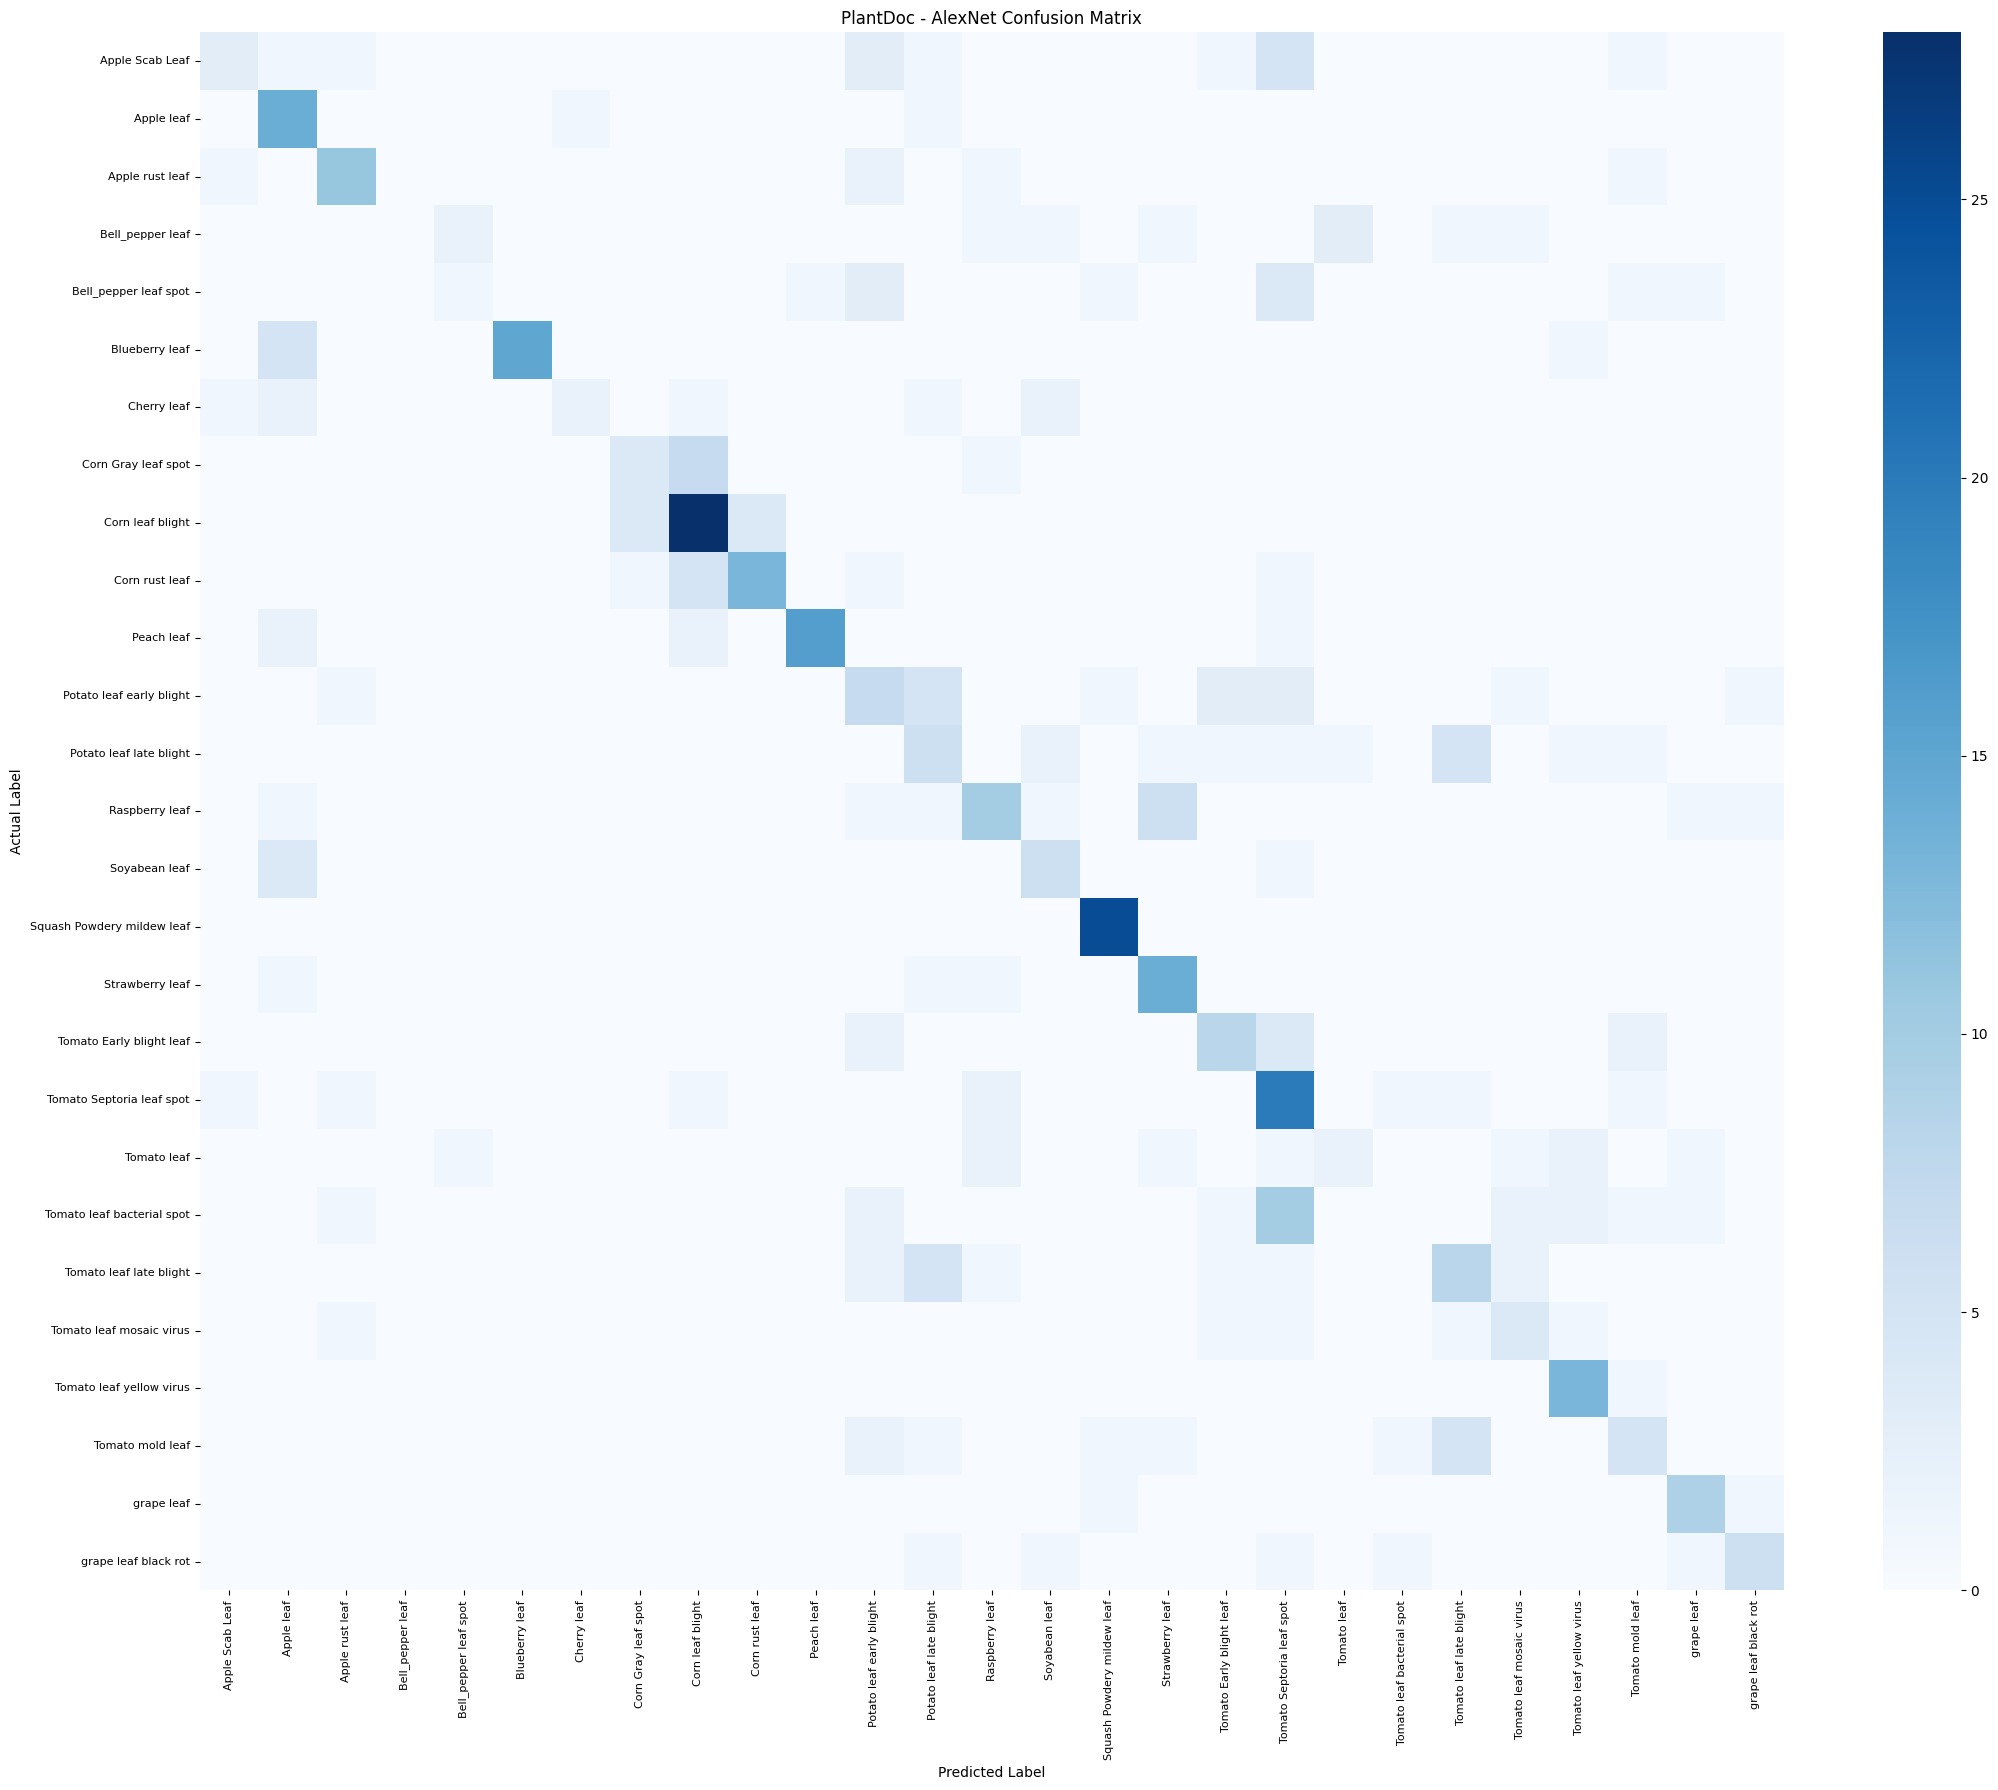

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_plant_alex = confusion_matrix(
    all_labels_plant_alex,
    all_preds_plant_alex
)

plt.figure(figsize=(22, 18))

sns.heatmap(
    cm_plant_alex,
    cmap="Blues",
    xticklabels=PLANTDOC_CLASSES,
    yticklabels=PLANTDOC_CLASSES
)

plt.title("PlantDoc - AlexNet Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

# Initialize pretrained EfficientNet-B0
model_plant_eff = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Replace final classification layer
model_plant_eff.classifier[1] = nn.Linear(
    model_plant_eff.classifier[1].in_features,
    NUM_PLANTDOC_CLASSES
)

# Move model to GPU
model_plant_eff = model_plant_eff.to(device)

# Loss function
criterion_plant_eff = nn.CrossEntropyLoss()

# Optimizer
optimizer_plant_eff = optim.Adam(
    model_plant_eff.parameters(),
    lr=0.0001
)

# Test model
model_plant_eff.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output = model_plant_eff(dummy)

print("PlantDoc EfficientNet-B0 Ready!")
print("Output Shape:", output.shape)
print("Device:", next(model_plant_eff.parameters()).device)
print("Number of Classes:", NUM_PLANTDOC_CLASSES)

PlantDoc EfficientNet-B0 Ready!
Output Shape: torch.Size([2, 27])
Device: cuda:0
Number of Classes: 27


In [34]:
import copy
import time

EPOCHS = 10

best_plant_eff_accuracy = 0.0

history_plant_eff = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_plant_eff_weights = copy.deepcopy(
    model_plant_eff.state_dict()
)

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    train_loss, train_acc = train_one_epoch(
        model_plant_eff,
        plant_train_loader,
        criterion_plant_eff,
        optimizer_plant_eff,
        device
    )

    # Validation
    val_loss, val_acc = validate_one_epoch(
        model_plant_eff,
        plant_valid_loader,
        criterion_plant_eff,
        device
    )

    # Save history
    history_plant_eff["train_loss"].append(train_loss)
    history_plant_eff["train_accuracy"].append(train_acc)
    history_plant_eff["val_loss"].append(val_loss)
    history_plant_eff["val_accuracy"].append(val_acc)

    # Save best checkpoint
    if val_acc > best_plant_eff_accuracy:

        best_plant_eff_accuracy = val_acc

        best_plant_eff_weights = copy.deepcopy(
            model_plant_eff.state_dict()
        )

        torch.save(
            best_plant_eff_weights,
            "/kaggle/working/best_efficientnet_plantdoc.pth"
        )

    elapsed = time.time() - start_time

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Time: {elapsed:.2f} seconds")

print("\nPlantDoc EfficientNet-B0 Training Completed!")
print(
    f"Best Validation Accuracy: "
    f"{best_plant_eff_accuracy:.2f}%"
)


Epoch [1/10]
Train Loss: 3.0743
Train Accuracy: 18.00%
Validation Loss: 2.6515
Validation Accuracy: 35.50%
Time: 83.07 seconds

Epoch [2/10]
Train Loss: 2.4614
Train Accuracy: 39.37%
Validation Loss: 2.0388
Validation Accuracy: 46.32%
Time: 82.56 seconds

Epoch [3/10]
Train Loss: 1.9437
Train Accuracy: 49.84%
Validation Loss: 1.6009
Validation Accuracy: 52.81%
Time: 80.21 seconds

Epoch [4/10]
Train Loss: 1.5842
Train Accuracy: 55.80%
Validation Loss: 1.3559
Validation Accuracy: 58.87%
Time: 81.60 seconds

Epoch [5/10]
Train Loss: 1.3115
Train Accuracy: 62.85%
Validation Loss: 1.2329
Validation Accuracy: 61.90%
Time: 81.05 seconds

Epoch [6/10]
Train Loss: 1.1622
Train Accuracy: 67.73%
Validation Loss: 1.1284
Validation Accuracy: 63.64%
Time: 80.95 seconds

Epoch [7/10]
Train Loss: 1.0394
Train Accuracy: 70.17%
Validation Loss: 1.0425
Validation Accuracy: 65.80%
Time: 80.71 seconds

Epoch [8/10]
Train Loss: 0.9348
Train Accuracy: 71.69%
Validation Loss: 0.9782
Validation Accuracy: 67.

In [35]:
model_plant_eff.load_state_dict(
    torch.load(
        "/kaggle/working/best_efficientnet_plantdoc.pth",
        map_location=device,
        weights_only=True
    )
)

model_plant_eff = model_plant_eff.to(device)
model_plant_eff.eval()

print("Best PlantDoc EfficientNet-B0 checkpoint loaded!")
print("Best Validation Accuracy:", best_plant_eff_accuracy)

Best PlantDoc EfficientNet-B0 checkpoint loaded!
Best Validation Accuracy: 68.83116883116882


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model_plant_eff.eval()

all_labels_plant_eff = []
all_preds_plant_eff = []

with torch.no_grad():
    for images, labels in plant_valid_loader:

        images = images.to(device)

        outputs = model_plant_eff(images)
        _, predicted = torch.max(outputs, 1)

        all_labels_plant_eff.extend(labels.numpy())
        all_preds_plant_eff.extend(predicted.cpu().numpy())

# Calculate metrics
accuracy_eff_plant = accuracy_score(
    all_labels_plant_eff,
    all_preds_plant_eff
)

precision_eff_plant = precision_score(
    all_labels_plant_eff,
    all_preds_plant_eff,
    average="macro",
    zero_division=0
)

recall_eff_plant = recall_score(
    all_labels_plant_eff,
    all_preds_plant_eff,
    average="macro",
    zero_division=0
)

f1_eff_plant = f1_score(
    all_labels_plant_eff,
    all_preds_plant_eff,
    average="macro",
    zero_division=0
)

print("PlantDoc EfficientNet-B0 Evaluation Results")
print("=" * 50)

print(f"Accuracy:  {accuracy_eff_plant * 100:.2f}%")
print(f"Precision: {precision_eff_plant * 100:.2f}%")
print(f"Recall:    {recall_eff_plant * 100:.2f}%")
print(f"F1-Score:  {f1_eff_plant * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels_plant_eff,
    all_preds_plant_eff,
    labels=list(range(NUM_PLANTDOC_CLASSES)),
    target_names=PLANTDOC_CLASSES,
    digits=4,
    zero_division=0
))

PlantDoc EfficientNet-B0 Evaluation Results
Accuracy:  68.83%
Precision: 67.14%
Recall:    67.17%
F1-Score:  66.19%

Classification Report:

                            precision    recall  f1-score   support

           Apple Scab Leaf     0.6667    0.5000    0.5714        16
                Apple leaf     0.6842    0.8125    0.7429        16
           Apple rust leaf     0.9286    0.8125    0.8667        16
          Bell_pepper leaf     0.5000    0.6000    0.5455        10
     Bell_pepper leaf spot     0.7500    0.5000    0.6000        12
            Blueberry leaf     0.7308    0.9048    0.8085        21
               Cherry leaf     0.7500    0.3333    0.4615         9
       Corn Gray leaf spot     0.5455    0.5000    0.5217        12
          Corn leaf blight     0.8333    0.8333    0.8333        36
            Corn rust leaf     0.8333    0.9524    0.8889        21
                Peach leaf     0.8182    0.8571    0.8372        21
  Potato leaf early blight     0.2500    0

In [38]:
from pathlib import Path

RICE_ORIGINAL = Path(
    "/kaggle/input/datasets/meerqamar/riceyleafdisease/"
    "RiceyLeafDisease An Extensive Image Dataset of Diverse Rice Leaf Diseases from Different Regions of Bangladesh/"
    "Original/Original Images/Original Images"
)

print("Dataset exists:", RICE_ORIGINAL.exists())
print("\nRice Disease Classes:")

for class_dir in sorted(RICE_ORIGINAL.iterdir()):
    if class_dir.is_dir():
        image_count = len([
            f for f in class_dir.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ])
        print(f"{class_dir.name}: {image_count} images")

Dataset exists: True

Rice Disease Classes:
Bacterial Leaf Blight: 180 images
Brown Spot: 267 images
Healthy Rice Leaf: 157 images
Leaf Blast: 305 images
Leaf scald: 189 images
Narrow Brown Leaf Spot: 117 images
Rice Hispa: 215 images
Sheath Blight: 271 images


In [40]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from collections import Counter
import numpy as np

# Image transformations
rice_train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

rice_valid_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load original dataset
rice_dataset = datasets.ImageFolder(
    root=str(RICE_ORIGINAL)
)

RICE_CLASSES = rice_dataset.classes
NUM_RICE_CLASSES = len(RICE_CLASSES)

# Stratified split
indices = np.arange(len(rice_dataset))
labels = np.array(rice_dataset.targets)

train_indices, valid_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Separate datasets with different transforms
rice_train_full = datasets.ImageFolder(
    root=str(RICE_ORIGINAL),
    transform=rice_train_transform
)

rice_valid_full = datasets.ImageFolder(
    root=str(RICE_ORIGINAL),
    transform=rice_valid_transform
)

rice_train_dataset = Subset(rice_train_full, train_indices)
rice_valid_dataset = Subset(rice_valid_full, valid_indices)

# DataLoaders
rice_train_loader = DataLoader(
    rice_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

rice_valid_loader = DataLoader(
    rice_valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Classes:", RICE_CLASSES)
print("Number of Classes:", NUM_RICE_CLASSES)
print("Training Images:", len(rice_train_dataset))
print("Validation Images:", len(rice_valid_dataset))

print("\nTraining Distribution:")
print(Counter(labels[train_indices]))

print("\nValidation Distribution:")
print(Counter(labels[valid_indices]))

Classes: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Narrow Brown Leaf Spot', 'Rice Hispa', 'Sheath Blight']
Number of Classes: 8
Training Images: 1360
Validation Images: 341

Training Distribution:
Counter({np.int64(3): 244, np.int64(7): 217, np.int64(1): 213, np.int64(6): 172, np.int64(4): 151, np.int64(0): 144, np.int64(2): 125, np.int64(5): 94})

Validation Distribution:
Counter({np.int64(3): 61, np.int64(7): 54, np.int64(1): 54, np.int64(6): 43, np.int64(4): 38, np.int64(0): 36, np.int64(2): 32, np.int64(5): 23})


In [41]:
# Get one training batch
images, labels = next(iter(rice_train_loader))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)
print("Image Data Type:", images.dtype)
print("Label Data Type:", labels.dtype)

print("\nDevice:", device)
print("Number of Classes:", NUM_RICE_CLASSES)

Image Batch Shape: torch.Size([32, 3, 224, 224])
Label Batch Shape: torch.Size([32])
Image Data Type: torch.float32
Label Data Type: torch.int64

Device: cuda
Number of Classes: 8


In [43]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import alexnet, AlexNet_Weights

# Load pretrained AlexNet
model_rice_alex = alexnet(
    weights=AlexNet_Weights.DEFAULT
)

# Replace final classification layer
model_rice_alex.classifier[6] = nn.Linear(
    model_rice_alex.classifier[6].in_features,
    NUM_RICE_CLASSES
)

# Move model to GPU
model_rice_alex = model_rice_alex.to(device)

# Loss function
criterion_rice_alex = nn.CrossEntropyLoss()

# Optimizer
optimizer_rice_alex = optim.Adam(
    model_rice_alex.parameters(),
    lr=0.0001
)

print("AlexNet initialized successfully!")
print("Number of Classes:", NUM_RICE_CLASSES)
print("Final Layer:", model_rice_alex.classifier[6])
print("Device:", next(model_rice_alex.parameters()).device)

AlexNet initialized successfully!
Number of Classes: 8
Final Layer: Linear(in_features=4096, out_features=8, bias=True)
Device: cuda:0


In [44]:
model_rice_alex.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output = model_rice_alex(dummy)

print("Input Shape:", dummy.shape)
print("Output Shape:", output.shape)

Input Shape: torch.Size([2, 3, 224, 224])
Output Shape: torch.Size([2, 8])


In [45]:
EPOCHS = 10

rice_alex_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_rice_alex_acc = 0.0

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model_rice_alex,
        rice_train_loader,
        criterion_rice_alex,
        optimizer_rice_alex,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model_rice_alex,
        rice_valid_loader,
        criterion_rice_alex,
        device
    )

    rice_alex_history["train_loss"].append(train_loss)
    rice_alex_history["train_acc"].append(train_acc)
    rice_alex_history["val_loss"].append(val_loss)
    rice_alex_history["val_acc"].append(val_acc)

    # Save best model
    if val_acc > best_rice_alex_acc:
        best_rice_alex_acc = val_acc

        torch.save(
            model_rice_alex.state_dict(),
            "/kaggle/working/best_alexnet_rice.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

print("\nTraining Completed!")
print(f"Best Validation Accuracy: {best_rice_alex_acc:.2f}%")


Epoch [1/10] Train Loss: 1.5160 | Train Acc: 46.18% | Val Loss: 0.9182 | Val Acc: 65.98%
Epoch [2/10] Train Loss: 1.0142 | Train Acc: 63.16% | Val Loss: 0.7519 | Val Acc: 73.31%
Epoch [3/10] Train Loss: 0.9156 | Train Acc: 68.31% | Val Loss: 0.6750 | Val Acc: 75.07%
Epoch [4/10] Train Loss: 0.7999 | Train Acc: 71.47% | Val Loss: 0.6409 | Val Acc: 76.83%
Epoch [5/10] Train Loss: 0.7206 | Train Acc: 73.75% | Val Loss: 0.6037 | Val Acc: 78.30%
Epoch [6/10] Train Loss: 0.6375 | Train Acc: 77.28% | Val Loss: 0.5651 | Val Acc: 81.23%
Epoch [7/10] Train Loss: 0.6225 | Train Acc: 79.41% | Val Loss: 0.6700 | Val Acc: 77.13%
Epoch [8/10] Train Loss: 0.6212 | Train Acc: 78.16% | Val Loss: 0.5973 | Val Acc: 81.52%
Epoch [9/10] Train Loss: 0.5418 | Train Acc: 80.96% | Val Loss: 0.6172 | Val Acc: 80.65%
Epoch [10/10] Train Loss: 0.5434 | Train Acc: 80.66% | Val Loss: 0.4573 | Val Acc: 85.92%

Training Completed!
Best Validation Accuracy: 85.92%


In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best checkpoint
model_rice_alex.load_state_dict(
    torch.load(
        "/kaggle/working/best_alexnet_rice.pth",
        map_location=device,
        weights_only=True
    )
)

model_rice_alex.eval()

all_labels_rice_alex = []
all_preds_rice_alex = []

with torch.no_grad():
    for images, labels in rice_valid_loader:

        images = images.to(device)

        outputs = model_rice_alex(images)
        _, predicted = torch.max(outputs, 1)

        all_labels_rice_alex.extend(labels.numpy())
        all_preds_rice_alex.extend(predicted.cpu().numpy())

# Calculate metrics
accuracy_rice_alex = accuracy_score(
    all_labels_rice_alex,
    all_preds_rice_alex
)

precision_rice_alex = precision_score(
    all_labels_rice_alex,
    all_preds_rice_alex,
    average="macro",
    zero_division=0
)

recall_rice_alex = recall_score(
    all_labels_rice_alex,
    all_preds_rice_alex,
    average="macro",
    zero_division=0
)

f1_rice_alex = f1_score(
    all_labels_rice_alex,
    all_preds_rice_alex,
    average="macro",
    zero_division=0
)

print("Rice Leaf Disease - AlexNet Evaluation Results")
print("=" * 55)

print(f"Accuracy:  {accuracy_rice_alex * 100:.2f}%")
print(f"Precision: {precision_rice_alex * 100:.2f}%")
print(f"Recall:    {recall_rice_alex * 100:.2f}%")
print(f"F1-Score:  {f1_rice_alex * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels_rice_alex,
    all_preds_rice_alex,
    labels=list(range(NUM_RICE_CLASSES)),
    target_names=RICE_CLASSES,
    digits=4,
    zero_division=0
))

Rice Leaf Disease - AlexNet Evaluation Results
Accuracy:  85.92%
Precision: 85.41%
Recall:    84.67%
F1-Score:  84.66%

Classification Report:

                        precision    recall  f1-score   support

 Bacterial Leaf Blight     0.7941    0.7500    0.7714        36
            Brown Spot     0.8846    0.8519    0.8679        54
     Healthy Rice Leaf     0.9688    0.9688    0.9688        32
            Leaf Blast     0.8000    0.8525    0.8254        61
            Leaf scald     0.8929    0.6579    0.7576        38
Narrow Brown Leaf Spot     0.6071    0.7391    0.6667        23
            Rice Hispa     1.0000    0.9535    0.9762        43
         Sheath Blight     0.8852    1.0000    0.9391        54

              accuracy                         0.8592       341
             macro avg     0.8541    0.8467    0.8466       341
          weighted avg     0.8647    0.8592    0.8586       341



In [47]:
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

# Load pretrained EfficientNet-B0
model_rice_eff = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Replace final classification layer
model_rice_eff.classifier[1] = nn.Linear(
    model_rice_eff.classifier[1].in_features,
    NUM_RICE_CLASSES
)

# Move model to GPU
model_rice_eff = model_rice_eff.to(device)

# Loss function
criterion_rice_eff = nn.CrossEntropyLoss()

# Optimizer
optimizer_rice_eff = optim.Adam(
    model_rice_eff.parameters(),
    lr=0.0001
)

print("EfficientNet-B0 initialized successfully!")
print("Number of Classes:", NUM_RICE_CLASSES)
print("Final Layer:", model_rice_eff.classifier[1])
print("Device:", next(model_rice_eff.parameters()).device)

EfficientNet-B0 initialized successfully!
Number of Classes: 8
Final Layer: Linear(in_features=1280, out_features=8, bias=True)
Device: cuda:0


In [48]:
model_rice_eff.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output = model_rice_eff(dummy)

print("Input Shape:", dummy.shape)
print("Output Shape:", output.shape)

Input Shape: torch.Size([2, 3, 224, 224])
Output Shape: torch.Size([2, 8])


In [49]:
EPOCHS = 10

rice_eff_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best checkpoint
model_rice_eff.load_state_dict(
    torch.load(
        "/kaggle/working/best_efficientnet_rice.pth",
        map_location=device,
        weights_only=True
    )
)

model_rice_eff.eval()

all_labels_rice_eff = []
all_preds_rice_eff = []

with torch.no_grad():
    for images, labels in rice_valid_loader:

        images = images.to(device)

        outputs = model_rice_eff(images)
        _, predicted = torch.max(outputs, 1)

        all_labels_rice_eff.extend(labels.numpy())
        all_preds_rice_eff.extend(predicted.cpu().numpy())

# Calculate metrics
accuracy_rice_eff = accuracy_score(
    all_labels_rice_eff,
    all_preds_rice_eff
)

precision_rice_eff = precision_score(
    all_labels_rice_eff,
    all_preds_rice_eff,
    average="macro",
    zero_division=0
)

recall_rice_eff = recall_score(
    all_labels_rice_eff,
    all_preds_rice_eff,
    average="macro",
    zero_division=0
)

f1_rice_eff = f1_score(
    all_labels_rice_eff,
    all_preds_rice_eff,
    average="macro",
    zero_division=0
)

print("Rice Leaf Disease - EfficientNet-B0 Evaluation Results")
print("=" * 60)

print(f"Accuracy:  {accuracy_rice_eff * 100:.2f}%")
print(f"Precision: {precision_rice_eff * 100:.2f}%")
print(f"Recall:    {recall_rice_eff * 100:.2f}%")
print(f"F1-Score:  {f1_rice_eff * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels_rice_eff,
    all_preds_rice_eff,
    labels=list(range(NUM_RICE_CLASSES)),
    target_names=RICE_CLASSES,
    digits=4,
    zero_division=0
))

best_rice_eff_acc = 0.0

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model_rice_eff,
        rice_train_loader,
        criterion_rice_eff,
        optimizer_rice_eff,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model_rice_eff,
        rice_valid_loader,
        criterion_rice_eff,
        device
    )

    rice_eff_history["train_loss"].append(train_loss)
    rice_eff_history["train_acc"].append(train_acc)
    rice_eff_history["val_loss"].append(val_loss)
    rice_eff_history["val_acc"].append(val_acc)

    if val_acc > best_rice_eff_acc:
        best_rice_eff_acc = val_acc

        torch.save(
            model_rice_eff.state_dict(),
            "/kaggle/working/best_efficientnet_rice.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

print("\nTraining Completed!")
print(f"Best Validation Accuracy: {best_rice_eff_acc:.2f}%")

Epoch [1/10] Train Loss: 1.9236 | Train Acc: 32.57% | Val Loss: 1.5976 | Val Acc: 51.91%
Epoch [2/10] Train Loss: 1.4910 | Train Acc: 54.63% | Val Loss: 1.1678 | Val Acc: 61.58%
Epoch [3/10] Train Loss: 1.1482 | Train Acc: 62.87% | Val Loss: 0.8640 | Val Acc: 73.02%
Epoch [4/10] Train Loss: 0.9238 | Train Acc: 70.37% | Val Loss: 0.6906 | Val Acc: 77.71%
Epoch [5/10] Train Loss: 0.7968 | Train Acc: 73.68% | Val Loss: 0.6051 | Val Acc: 81.23%
Epoch [6/10] Train Loss: 0.6778 | Train Acc: 76.76% | Val Loss: 0.5332 | Val Acc: 83.87%
Epoch [7/10] Train Loss: 0.5899 | Train Acc: 80.51% | Val Loss: 0.4801 | Val Acc: 85.34%
Epoch [8/10] Train Loss: 0.5015 | Train Acc: 84.26% | Val Loss: 0.4548 | Val Acc: 85.92%
Epoch [9/10] Train Loss: 0.4794 | Train Acc: 84.63% | Val Loss: 0.4326 | Val Acc: 86.51%
Epoch [10/10] Train Loss: 0.4398 | Train Acc: 85.59% | Val Loss: 0.3897 | Val Acc: 88.27%

Training Completed!
Best Validation Accuracy: 88.27%


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best checkpoint
model_rice_eff.load_state_dict(
    torch.load(
        "/kaggle/working/best_efficientnet_rice.pth",
        map_location=device,
        weights_only=True
    )
)

model_rice_eff.eval()

all_labels_rice_eff = []
all_preds_rice_eff = []

with torch.no_grad():
    for images, labels in rice_valid_loader:

        images = images.to(device)

        outputs = model_rice_eff(images)
        _, predicted = torch.max(outputs, 1)

        all_labels_rice_eff.extend(labels.numpy())
        all_preds_rice_eff.extend(predicted.cpu().numpy())

# Calculate metrics
accuracy_rice_eff = accuracy_score(
    all_labels_rice_eff,
    all_preds_rice_eff
)

precision_rice_eff = precision_score(
    all_labels_rice_eff,
    all_preds_rice_eff,
    average="macro",
    zero_division=0
)

recall_rice_eff = recall_score(
    all_labels_rice_eff,
    all_preds_rice_eff,
    average="macro",
    zero_division=0
)

f1_rice_eff = f1_score(
    all_labels_rice_eff,
    all_preds_rice_eff,
    average="macro",
    zero_division=0
)

print("Rice Leaf Disease - EfficientNet-B0 Evaluation Results")
print("=" * 60)

print(f"Accuracy:  {accuracy_rice_eff * 100:.2f}%")
print(f"Precision: {precision_rice_eff * 100:.2f}%")
print(f"Recall:    {recall_rice_eff * 100:.2f}%")
print(f"F1-Score:  {f1_rice_eff * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels_rice_eff,
    all_preds_rice_eff,
    labels=list(range(NUM_RICE_CLASSES)),
    target_names=RICE_CLASSES,
    digits=4,
    zero_division=0
))

Rice Leaf Disease - EfficientNet-B0 Evaluation Results
Accuracy:  88.27%
Precision: 88.72%
Recall:    85.95%
F1-Score:  86.68%

Classification Report:

                        precision    recall  f1-score   support

 Bacterial Leaf Blight     0.6905    0.8056    0.7436        36
            Brown Spot     0.9400    0.8704    0.9038        54
     Healthy Rice Leaf     1.0000    0.9688    0.9841        32
            Leaf Blast     0.8485    0.9180    0.8819        61
            Leaf scald     0.7500    0.7895    0.7692        38
Narrow Brown Leaf Spot     0.9286    0.5652    0.7027        23
            Rice Hispa     0.9767    0.9767    0.9767        43
         Sheath Blight     0.9636    0.9815    0.9725        54

              accuracy                         0.8827       341
             macro avg     0.8872    0.8595    0.8668       341
          weighted avg     0.8893    0.8827    0.8820       341



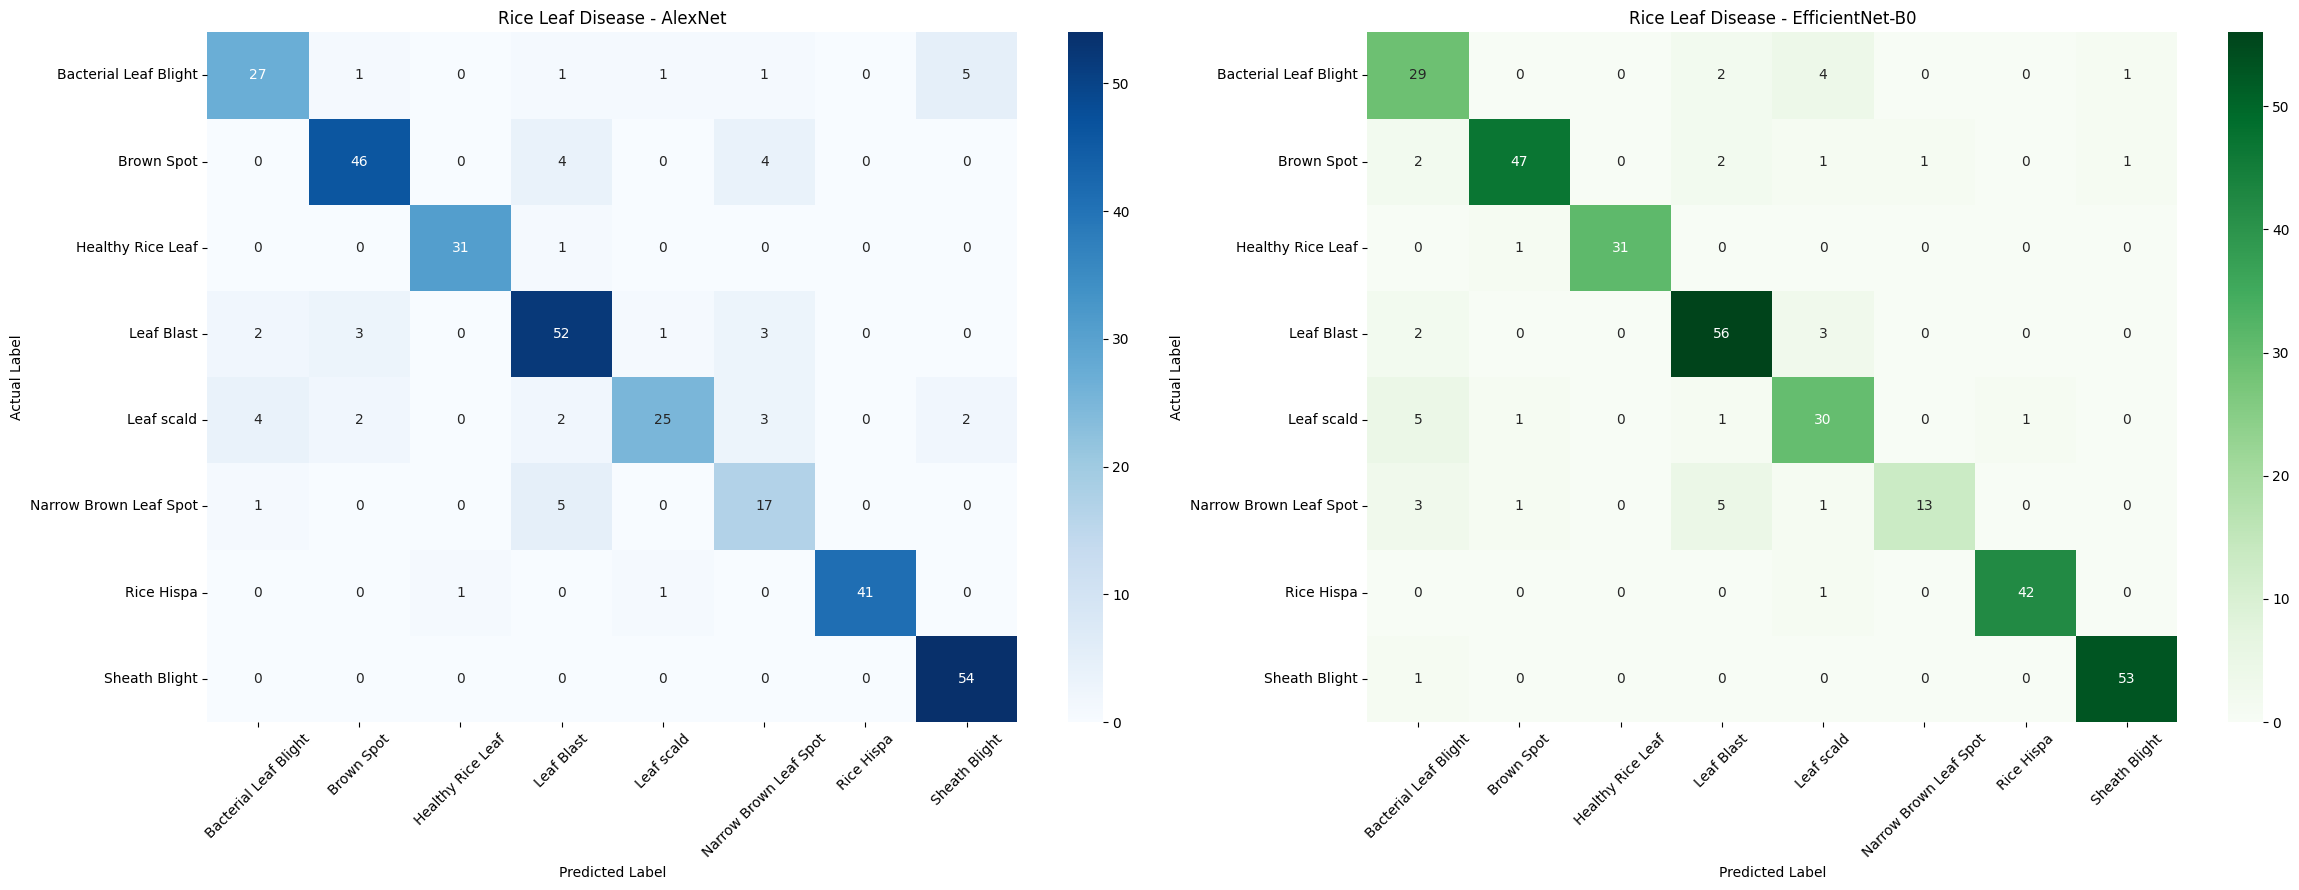

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrices
cm_rice_alex = confusion_matrix(
    all_labels_rice_alex,
    all_preds_rice_alex,
    labels=list(range(NUM_RICE_CLASSES))
)

cm_rice_eff = confusion_matrix(
    all_labels_rice_eff,
    all_preds_rice_eff,
    labels=list(range(NUM_RICE_CLASSES))
)

# Plot both matrices
fig, axes = plt.subplots(1, 2, figsize=(24, 9))

sns.heatmap(
    cm_rice_alex,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=RICE_CLASSES,
    yticklabels=RICE_CLASSES,
    ax=axes[0]
)

axes[0].set_title("Rice Leaf Disease - AlexNet")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")
axes[0].tick_params(axis="x", rotation=45)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    cm_rice_eff,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=RICE_CLASSES,
    yticklabels=RICE_CLASSES,
    ax=axes[1]
)

axes[1].set_title("Rice Leaf Disease - EfficientNet-B0")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


Evaluating: newplant_alexnet


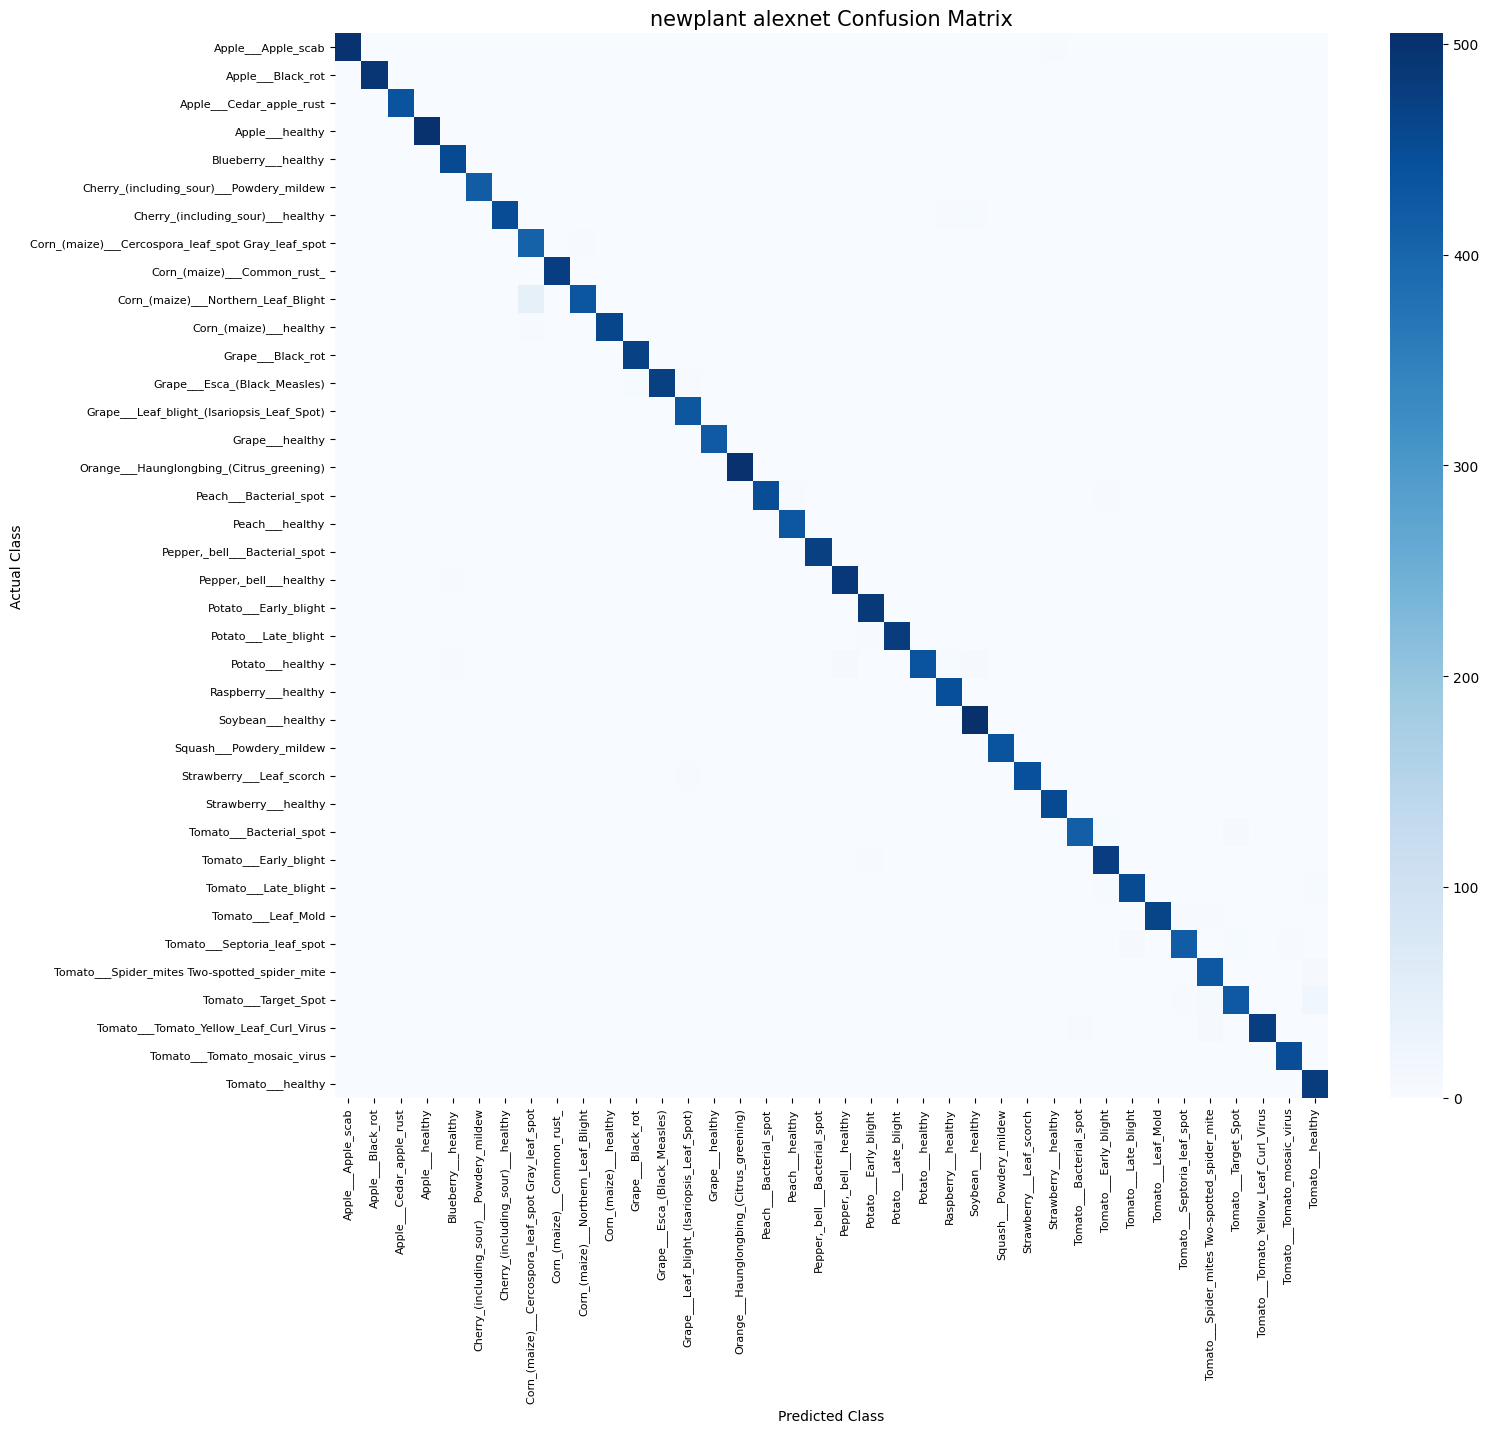

Correct predictions: 17343
Total images: 17572
Confusion matrix saved: /kaggle/working/final_project_results/newplant_alexnet_confusion_matrix.png
CSV saved: /kaggle/working/final_project_results/newplant_alexnet_confusion_matrix.csv

Evaluating: newplant_efficientnet


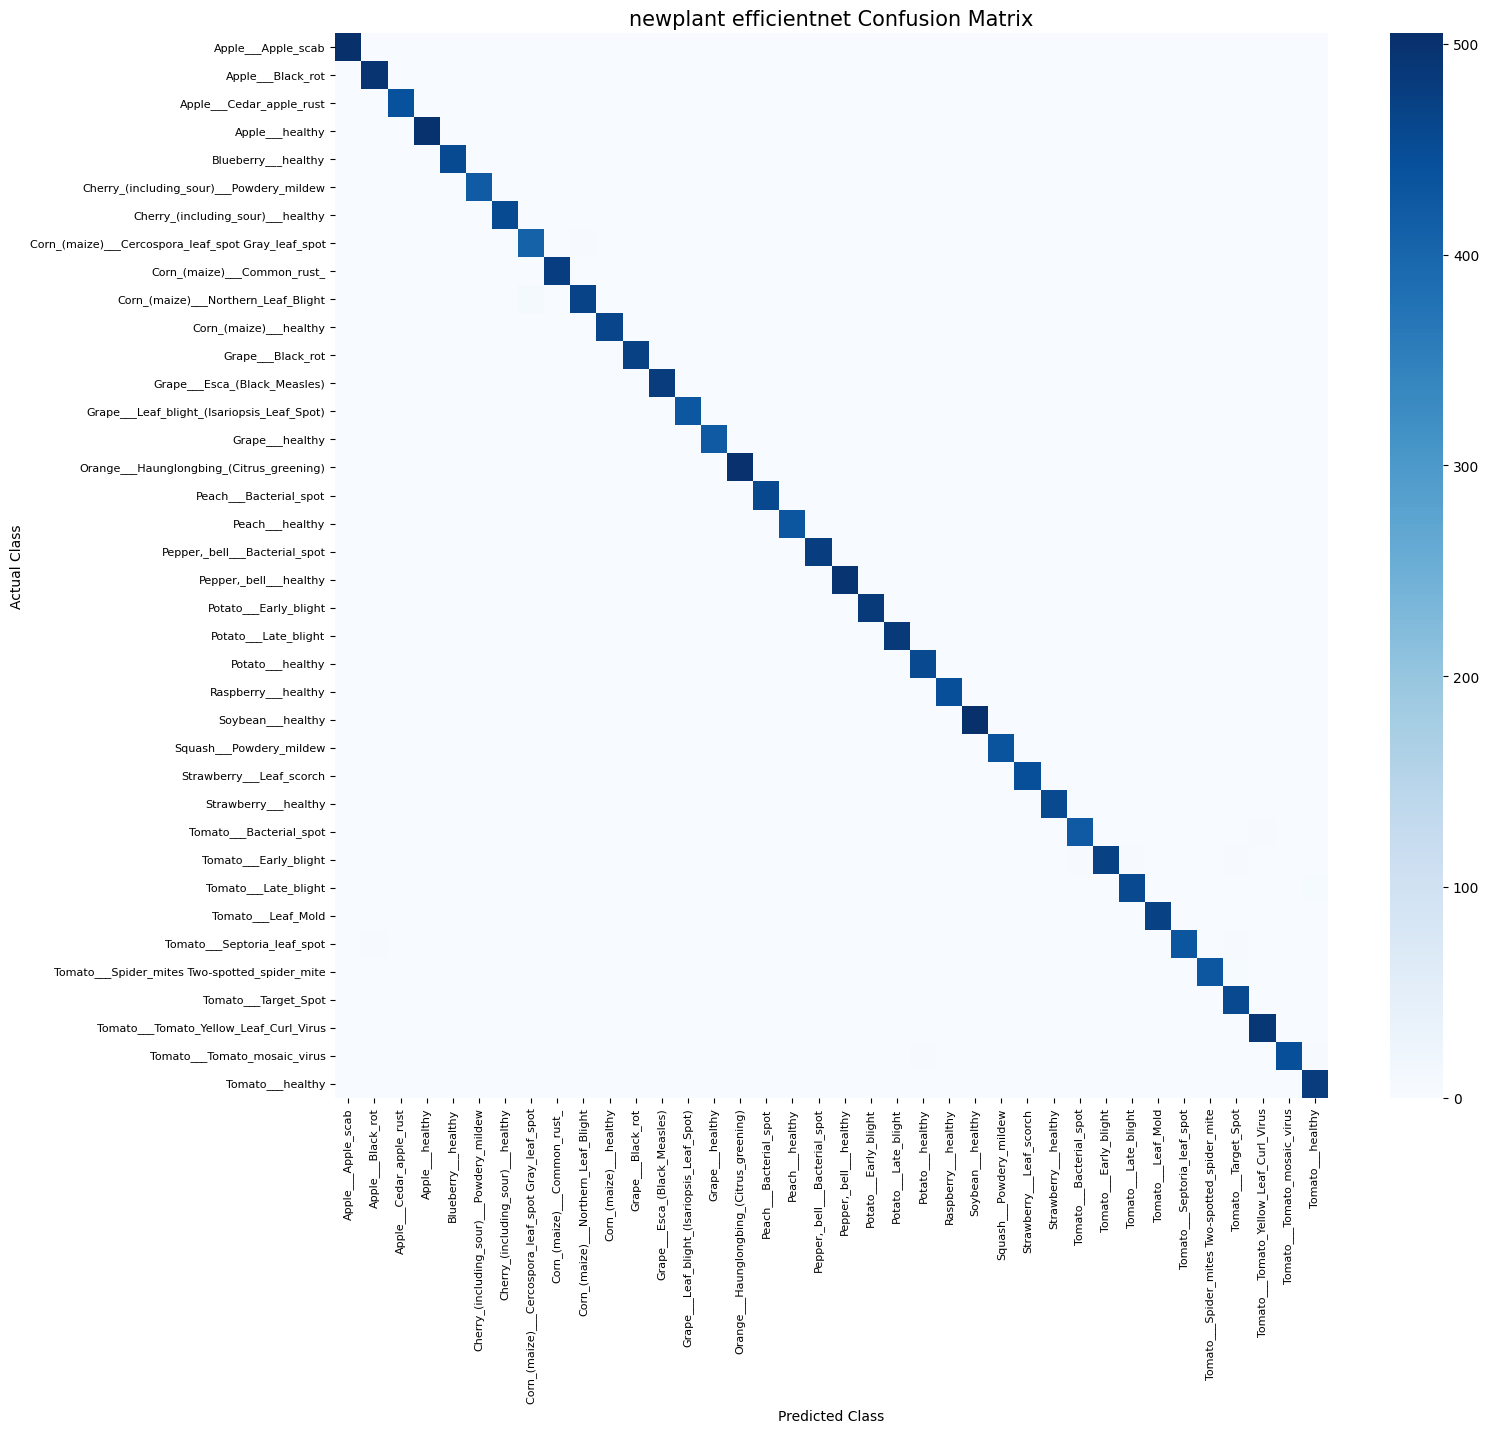

Correct predictions: 17527
Total images: 17572
Confusion matrix saved: /kaggle/working/final_project_results/newplant_efficientnet_confusion_matrix.png
CSV saved: /kaggle/working/final_project_results/newplant_efficientnet_confusion_matrix.csv

Evaluating: plantdoc_alexnet


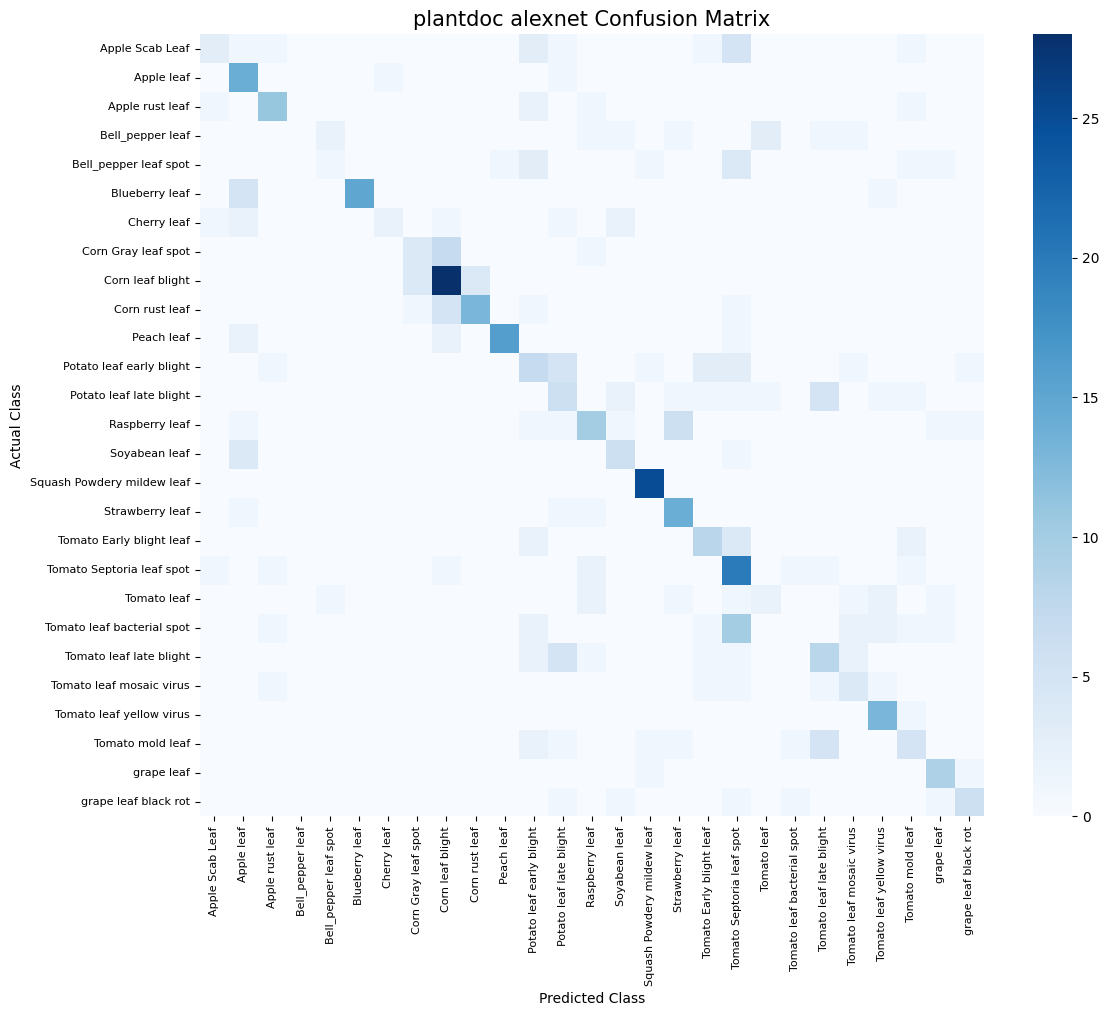

Correct predictions: 250
Total images: 462
Confusion matrix saved: /kaggle/working/final_project_results/plantdoc_alexnet_confusion_matrix.png
CSV saved: /kaggle/working/final_project_results/plantdoc_alexnet_confusion_matrix.csv

Evaluating: plantdoc_efficientnet


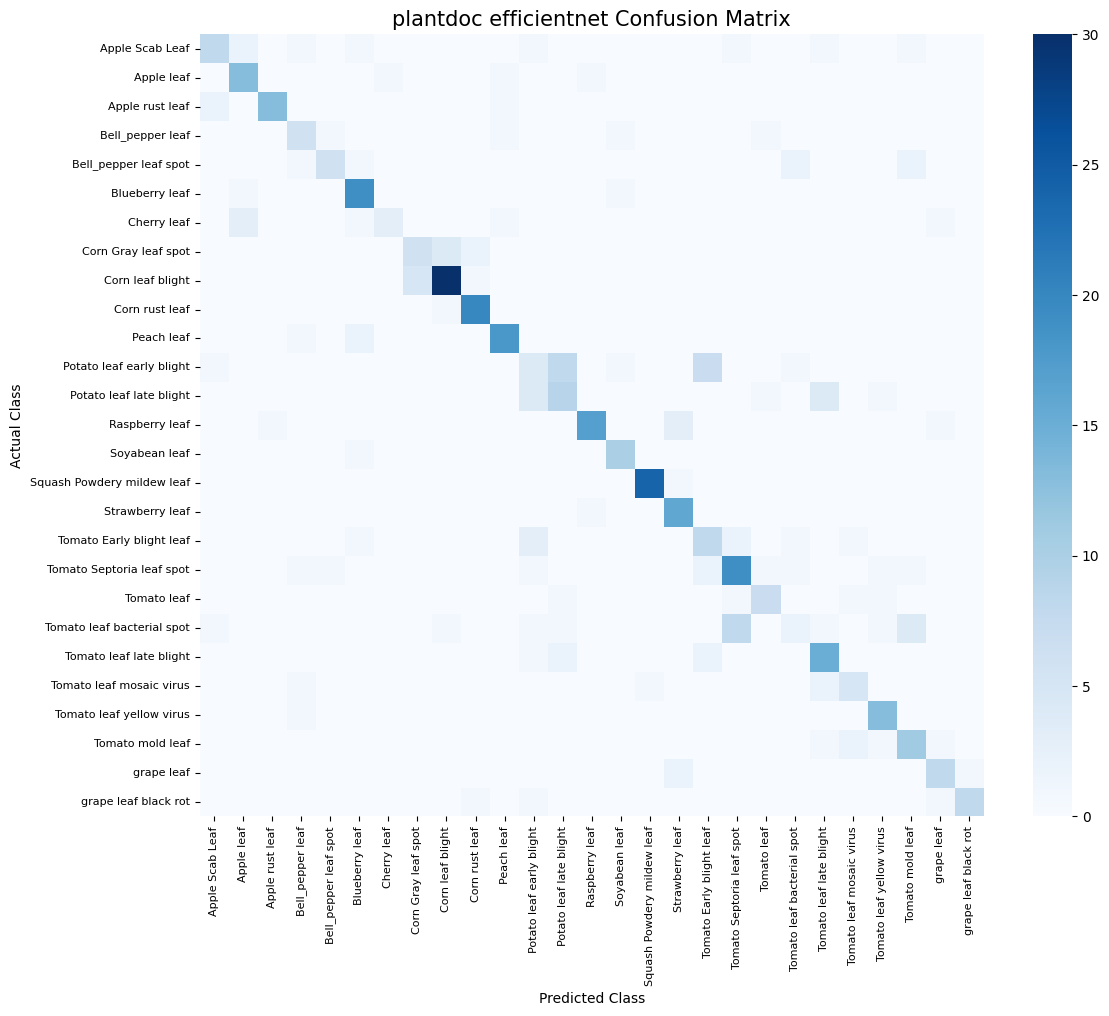

Correct predictions: 318
Total images: 462
Confusion matrix saved: /kaggle/working/final_project_results/plantdoc_efficientnet_confusion_matrix.png
CSV saved: /kaggle/working/final_project_results/plantdoc_efficientnet_confusion_matrix.csv

Evaluating: rice_alexnet


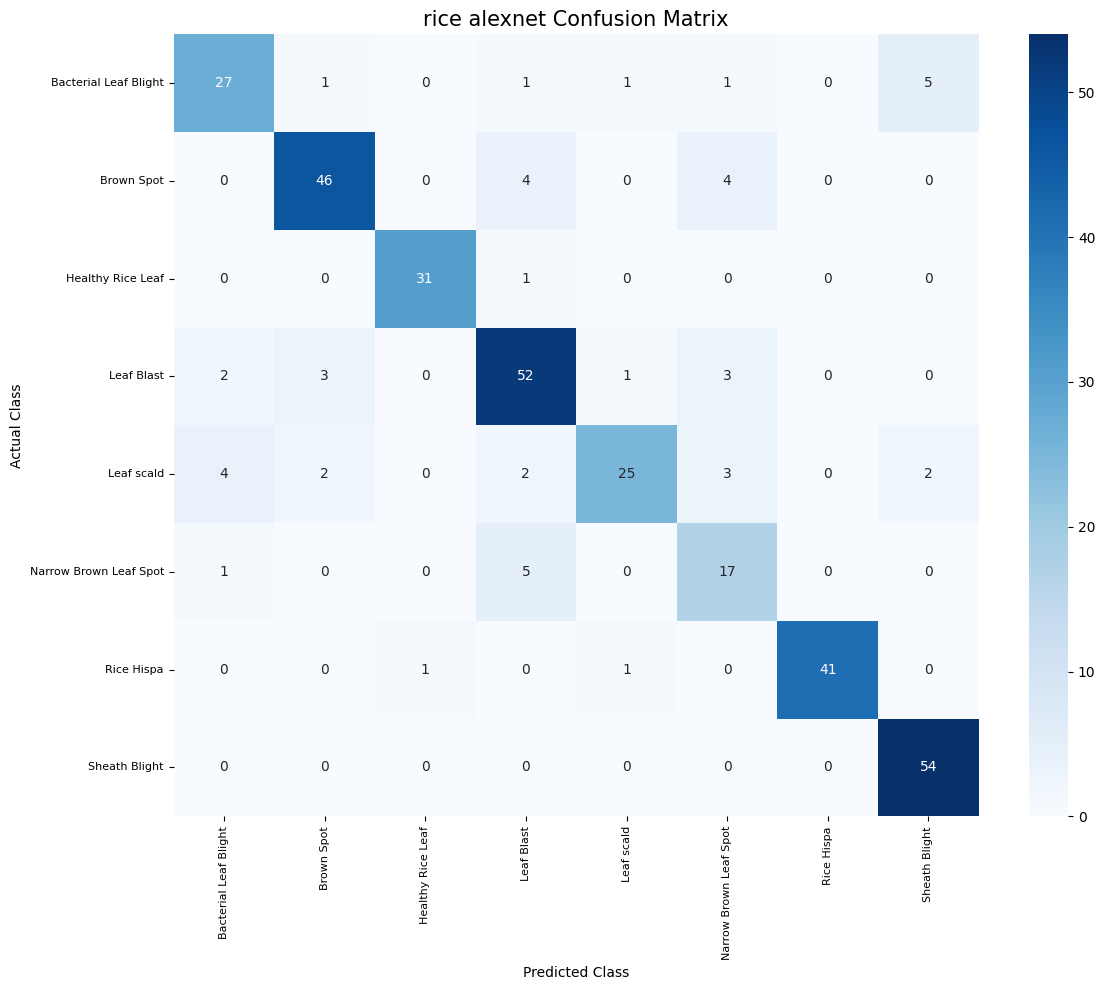

Correct predictions: 293
Total images: 341
Confusion matrix saved: /kaggle/working/final_project_results/rice_alexnet_confusion_matrix.png
CSV saved: /kaggle/working/final_project_results/rice_alexnet_confusion_matrix.csv

Evaluating: rice_efficientnet


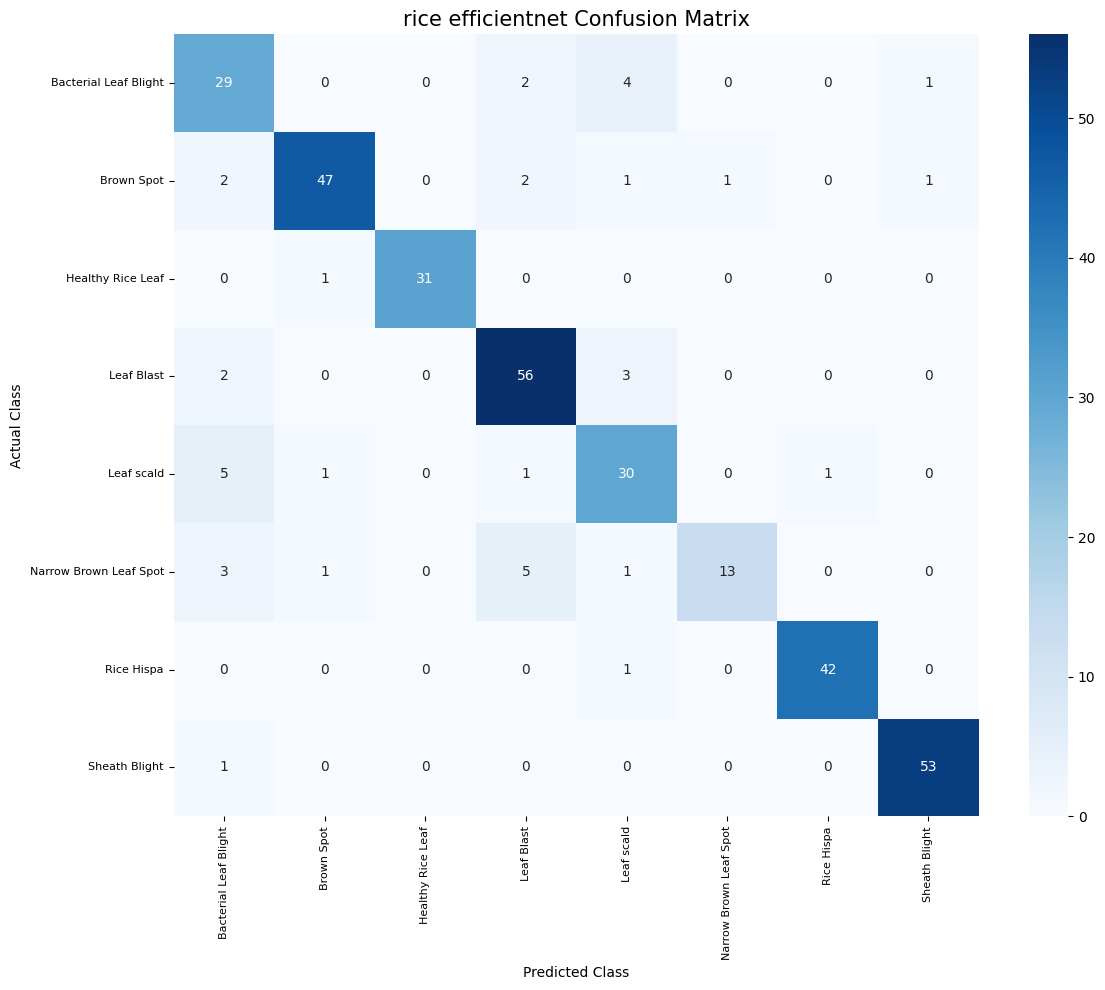

Correct predictions: 301
Total images: 341
Confusion matrix saved: /kaggle/working/final_project_results/rice_efficientnet_confusion_matrix.png
CSV saved: /kaggle/working/final_project_results/rice_efficientnet_confusion_matrix.csv

All six confusion matrices generated successfully!
Results directory: /kaggle/working/final_project_results


In [52]:
import os
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision.models import (
    alexnet,
    efficientnet_b0
)

from sklearn.metrics import confusion_matrix

# Output directory
OUTPUT_DIR = "/kaggle/working/final_project_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# -----------------------------------------
# 1. Model creation functions
# -----------------------------------------

def build_alexnet(num_classes):
    model = alexnet(weights=None)
    model.classifier[6] = nn.Linear(
        model.classifier[6].in_features,
        num_classes
    )
    return model


def build_efficientnet(num_classes):
    model = efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features,
        num_classes
    )
    return model


# -----------------------------------------
# 2. Evaluation and confusion matrix
# -----------------------------------------

def evaluate_and_save_cm(
    model_name,
    model_type,
    checkpoint_path,
    loader,
    class_names
):

    print(f"\nEvaluating: {model_name}")

    if model_type == "alexnet":
        model = build_alexnet(len(class_names))
    else:
        model = build_efficientnet(len(class_names))

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    model = model.to(device)
    model.eval()

    actual_labels = []
    predicted_labels = []

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            actual_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predictions.cpu().numpy())

    # Generate confusion matrix
    cm = confusion_matrix(
        actual_labels,
        predicted_labels,
        labels=list(range(len(class_names)))
    )

    # Save raw confusion matrix
    csv_path = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_confusion_matrix.csv"
    )

    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    ).to_csv(csv_path)

    # Plot confusion matrix
    n = len(class_names)

    fig, ax = plt.subplots(
        figsize=(max(12, n * 0.42), max(10, n * 0.38))
    )

    sns.heatmap(
        cm,
        annot=(n <= 10),
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(
        f"{model_name.replace('_', ' ')} Confusion Matrix",
        fontsize=15
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)

    plt.tight_layout()

    png_path = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_confusion_matrix.png"
    )

    plt.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Correct predictions:", cm.trace())
    print("Total images:", cm.sum())
    print("Confusion matrix saved:", png_path)
    print("CSV saved:", csv_path)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return cm


# -----------------------------------------
# 3. Run all six experiments
# -----------------------------------------

confusion_matrices = {}

experiments = [
    (
        "newplant_alexnet",
        "alexnet",
        "/kaggle/working/best_alexnet_newplant.pth",
        new_valid_loader,
        NEW_PLANT_CLASSES
    ),
    (
        "newplant_efficientnet",
        "efficientnet",
        "/kaggle/working/best_efficientnet_newplant.pth",
        new_valid_loader,
        NEW_PLANT_CLASSES
    ),
    (
        "plantdoc_alexnet",
        "alexnet",
        "/kaggle/working/best_alexnet_plantdoc.pth",
        plant_valid_loader,
        PLANTDOC_CLASSES
    ),
    (
        "plantdoc_efficientnet",
        "efficientnet",
        "/kaggle/working/best_efficientnet_plantdoc.pth",
        plant_valid_loader,
        PLANTDOC_CLASSES
    ),
    (
        "rice_alexnet",
        "alexnet",
        "/kaggle/working/best_alexnet_rice.pth",
        rice_valid_loader,
        RICE_CLASSES
    ),
    (
        "rice_efficientnet",
        "efficientnet",
        "/kaggle/working/best_efficientnet_rice.pth",
        rice_valid_loader,
        RICE_CLASSES
    )
]

for name, model_type, checkpoint, loader, classes in experiments:

    confusion_matrices[name] = evaluate_and_save_cm(
        model_name=name,
        model_type=model_type,
        checkpoint_path=checkpoint,
        loader=loader,
        class_names=classes
    )

print("\nAll six confusion matrices generated successfully!")
print("Results directory:", OUTPUT_DIR)

In [53]:
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from collections import Counter
import torch

# Official PlantDoc test directory
PLANTDOC_TEST = PLANTDOC_ROOT / "test"

# Same preprocessing used for validation
plant_test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class PlantDocOfficialTestDataset(Dataset):
    def __init__(self, root, class_to_idx, transform=None):
        self.root = Path(root)
        self.class_to_idx = class_to_idx
        self.transform = transform
        self.samples = []

        supported_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

        folder_names = {
            folder.name for folder in self.root.iterdir()
            if folder.is_dir()
        }

        unknown_folders = folder_names - set(class_to_idx.keys())

        if unknown_folders:
            raise ValueError(
                f"Unexpected test class folders: {sorted(unknown_folders)}"
            )

        for class_name, label in class_to_idx.items():
            class_folder = self.root / class_name

            if not class_folder.exists():
                print(f"Warning: Missing test folder: {class_name}")
                continue

            for image_path in class_folder.rglob("*"):
                if image_path.is_file() and image_path.suffix.lower() in supported_extensions:
                    self.samples.append((image_path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


plant_test_dataset = PlantDocOfficialTestDataset(
    root=PLANTDOC_TEST,
    class_to_idx=PLANTDOC_CLASS_TO_IDX,
    transform=plant_test_transform
)

plant_test_loader = DataLoader(
    plant_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Official PlantDoc Test Dataset")
print("=" * 40)
print("Total test images:", len(plant_test_dataset))
print("Number of classes:", len(PLANTDOC_CLASSES))

test_class_counts = Counter(
    PLANTDOC_CLASSES[label]
    for _, label in plant_test_dataset.samples
)

for class_name in PLANTDOC_CLASSES:
    print(f"{class_name}: {test_class_counts[class_name]}")

assert len(plant_test_dataset) > 0, "No test images found!"
assert len(PLANTDOC_CLASSES) == 27, "Expected 27 classes."

print("\nTest DataLoader is ready.")

Official PlantDoc Test Dataset
Total test images: 233
Number of classes: 27
Apple Scab Leaf: 10
Apple leaf: 9
Apple rust leaf: 10
Bell_pepper leaf: 8
Bell_pepper leaf spot: 9
Blueberry leaf: 11
Cherry leaf: 10
Corn Gray leaf spot: 3
Corn leaf blight: 12
Corn rust leaf: 10
Peach leaf: 9
Potato leaf early blight: 8
Potato leaf late blight: 8
Raspberry leaf: 7
Soyabean leaf: 8
Squash Powdery mildew leaf: 6
Strawberry leaf: 8
Tomato Early blight leaf: 9
Tomato Septoria leaf spot: 11
Tomato leaf: 8
Tomato leaf bacterial spot: 9
Tomato leaf late blight: 10
Tomato leaf mosaic virus: 10
Tomato leaf yellow virus: 6
Tomato mold leaf: 6
grape leaf: 10
grape leaf black rot: 8

Test DataLoader is ready.


In [54]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_trained_model(model_builder, checkpoint_path, num_classes):
    model = model_builder(num_classes=num_classes).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    # Support either a plain state_dict or a wrapped checkpoint
    if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        checkpoint = checkpoint["state_dict"]

    model.load_state_dict(checkpoint)
    model.eval()

    return model


def evaluate_official_test(model, loader, model_name):
    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            all_labels,
            all_predictions,
            average="weighted",
            zero_division=0
        )
    )

    print(f"\n{model_name} — Official PlantDoc Test Results")
    print("=" * 55)
    print(f"Accuracy:          {accuracy * 100:.2f}%")
    print(f"Macro Precision:   {precision * 100:.2f}%")
    print(f"Macro Recall:      {recall * 100:.2f}%")
    print(f"Macro F1-Score:    {f1 * 100:.2f}%")
    print(f"Weighted F1-Score: {weighted_f1 * 100:.2f}%")

    print("\nClassification Report:\n")

    print(classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(PLANTDOC_CLASSES))),
        target_names=PLANTDOC_CLASSES,
        zero_division=0
    ))

    return {
        "Model": model_name,
        "Accuracy": accuracy * 100,
        "Macro Precision": precision * 100,
        "Macro Recall": recall * 100,
        "Macro F1": f1 * 100,
        "Weighted F1": weighted_f1 * 100,
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions)
    }


# Load AlexNet
plantdoc_alexnet_test = load_trained_model(
    build_alexnet,
    "/kaggle/working/best_alexnet_plantdoc.pth",
    len(PLANTDOC_CLASSES)
)

# Load EfficientNet-B0
plantdoc_efficientnet_test = load_trained_model(
    build_efficientnet,
    "/kaggle/working/best_efficientnet_plantdoc.pth",
    len(PLANTDOC_CLASSES)
)

# Evaluate both models on the official test set
alexnet_test_results = evaluate_official_test(
    plantdoc_alexnet_test,
    plant_test_loader,
    "AlexNet"
)

efficientnet_test_results = evaluate_official_test(
    plantdoc_efficientnet_test,
    plant_test_loader,
    "EfficientNet-B0"
)


AlexNet — Official PlantDoc Test Results
Accuracy:          49.79%
Macro Precision:   47.93%
Macro Recall:      47.97%
Macro F1-Score:    44.85%
Weighted F1-Score: 46.32%

Classification Report:

                            precision    recall  f1-score   support

           Apple Scab Leaf       0.25      0.10      0.14        10
                Apple leaf       0.31      0.89      0.46         9
           Apple rust leaf       0.67      0.60      0.63        10
          Bell_pepper leaf       0.00      0.00      0.00         8
     Bell_pepper leaf spot       0.00      0.00      0.00         9
            Blueberry leaf       0.57      0.36      0.44        11
               Cherry leaf       0.50      0.30      0.38        10
       Corn Gray leaf spot       0.00      0.00      0.00         3
          Corn leaf blight       0.62      0.67      0.64        12
            Corn rust leaf       0.75      0.90      0.82        10
                Peach leaf       0.78      0.78      0

In [55]:
test_comparison = pd.DataFrame([
    {k: v for k, v in alexnet_test_results.items()
     if k not in ["labels", "predictions"]},

    {k: v for k, v in efficientnet_test_results.items()
     if k not in ["labels", "predictions"]}
])

print("PLANTDOC OFFICIAL TEST SET — MODEL COMPARISON")
display(test_comparison.round(2))

output_dir = Path("/kaggle/working/final_project_results")
output_dir.mkdir(parents=True, exist_ok=True)

test_comparison.to_csv(
    output_dir / "plantdoc_official_test_comparison.csv",
    index=False
)

PLANTDOC OFFICIAL TEST SET — MODEL COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,AlexNet,49.79,47.93,47.97,44.85,46.32
1,EfficientNet-B0,62.66,63.19,61.58,59.93,61.11


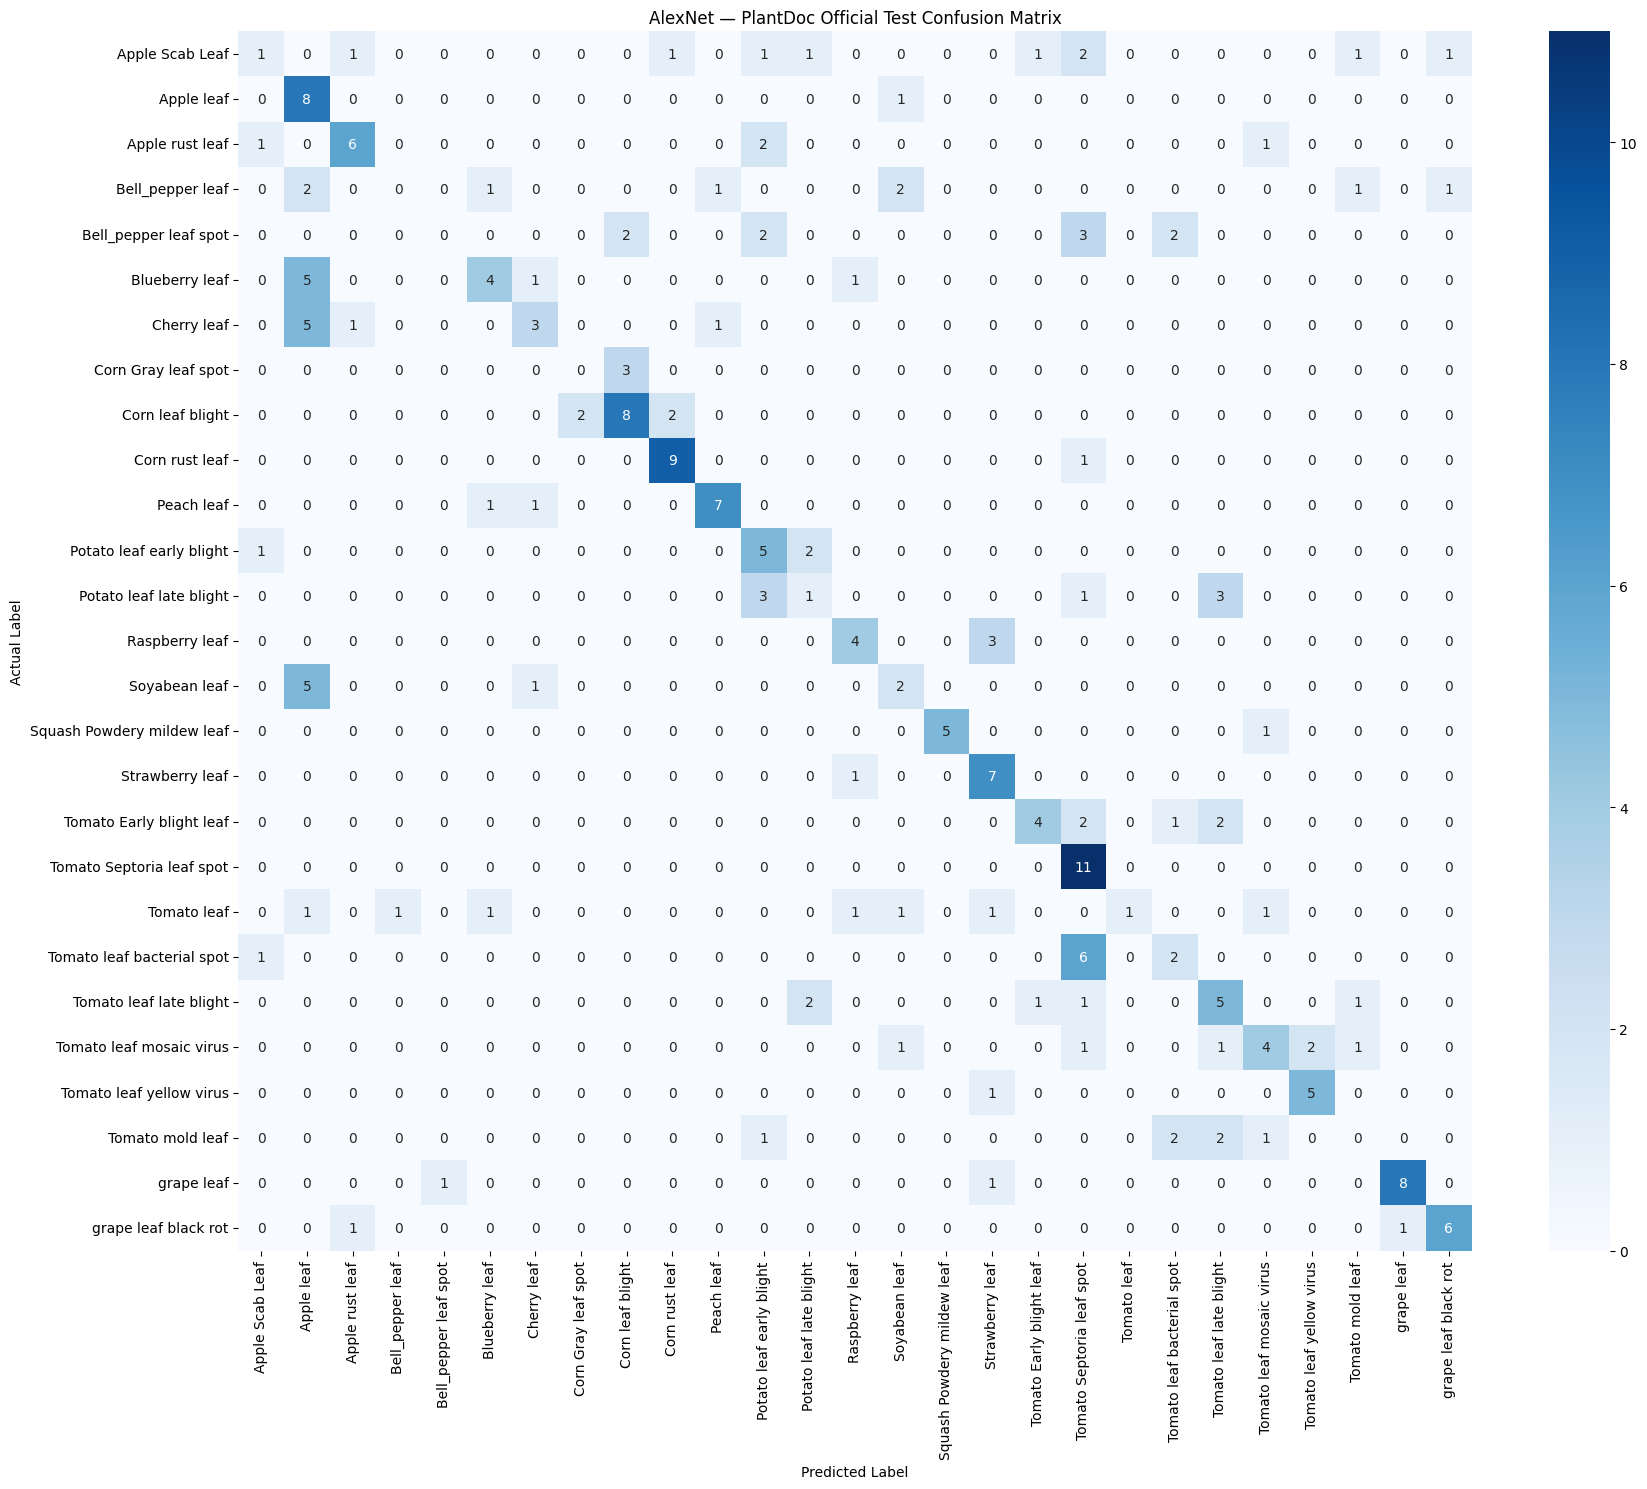

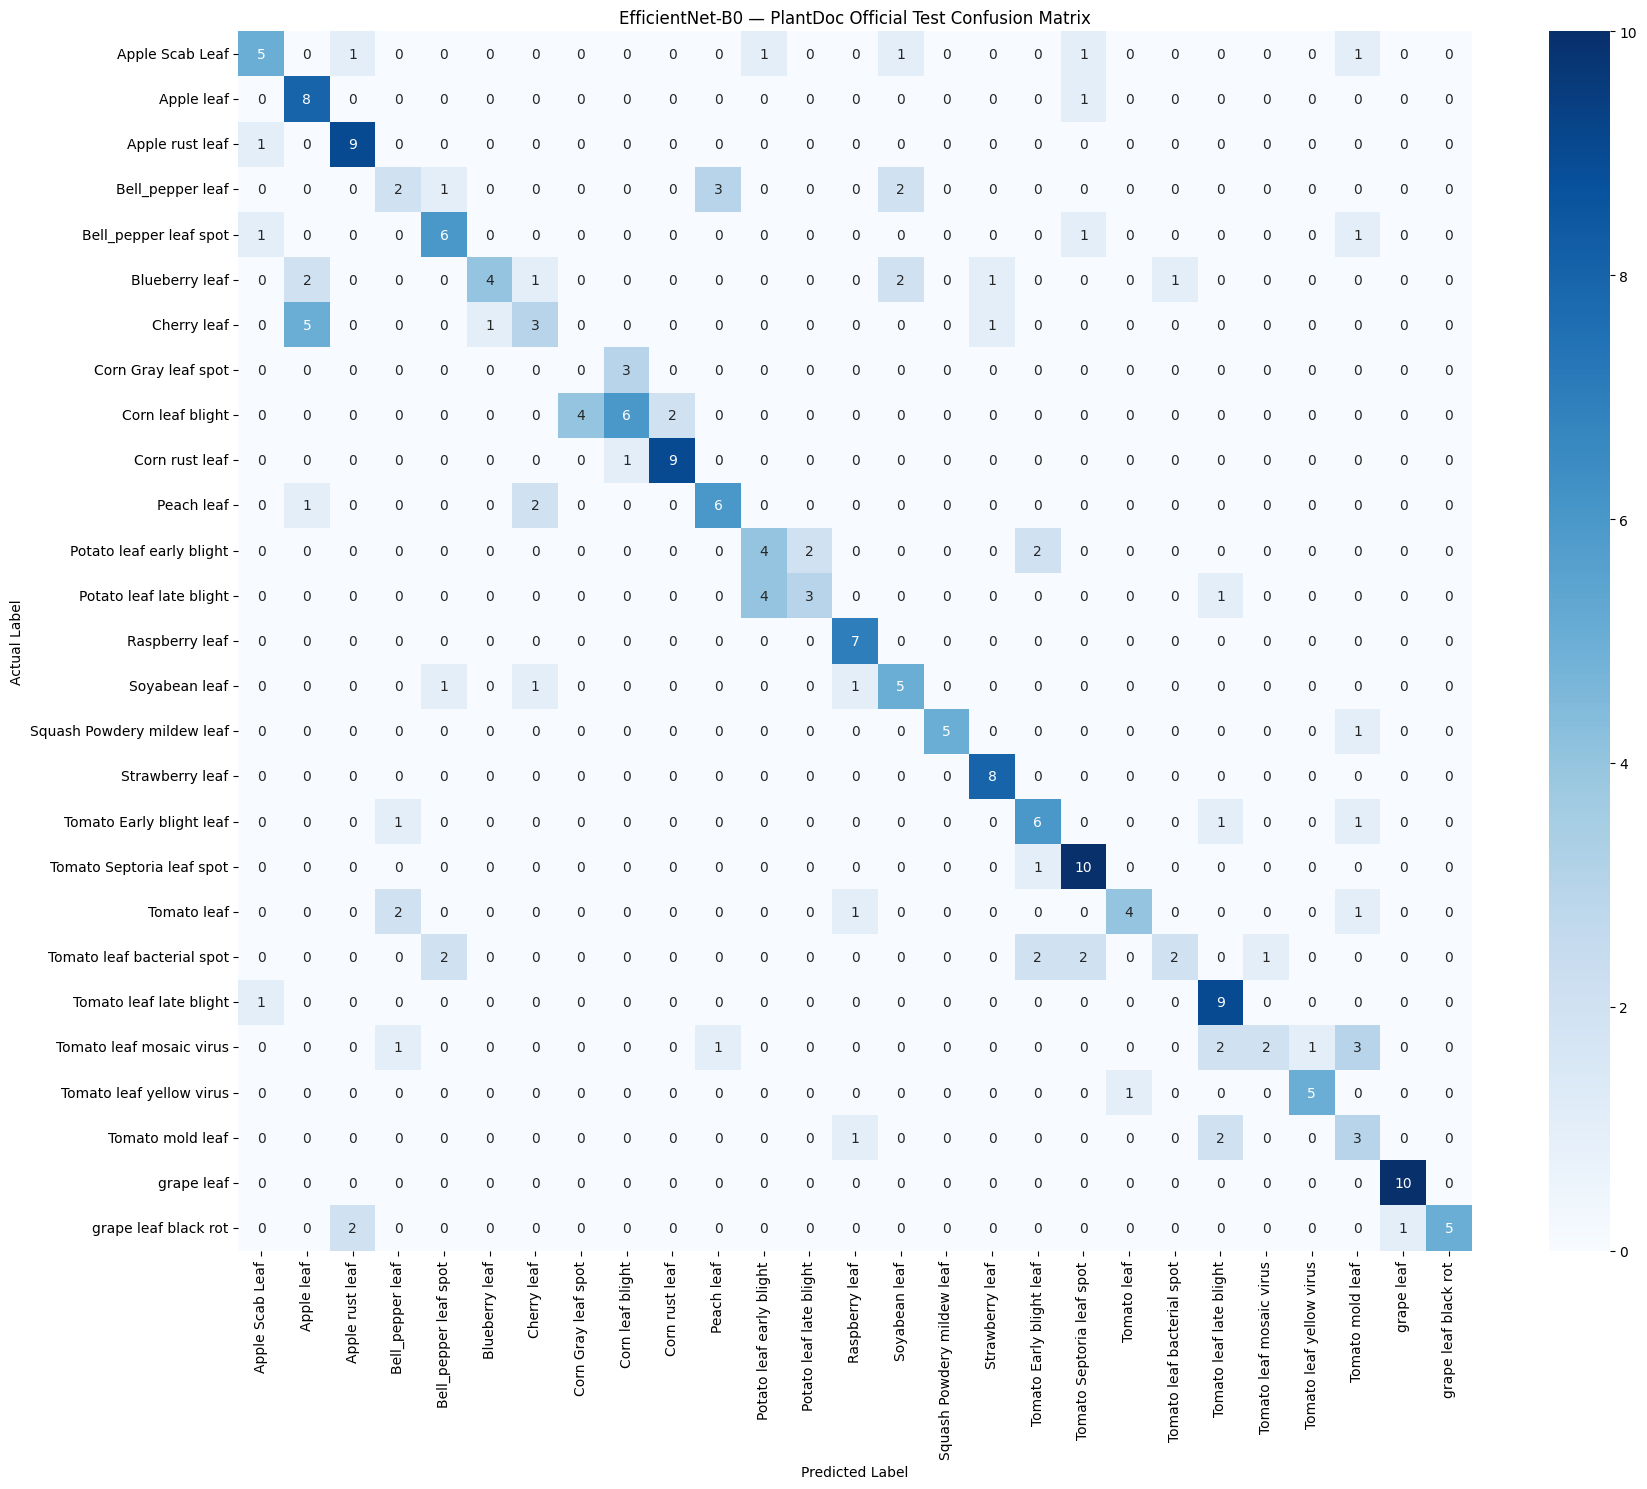

Official test comparison and confusion matrices saved.


In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

test_models = {
    "AlexNet": alexnet_test_results,
    "EfficientNet-B0": efficientnet_test_results
}

for model_name, results in test_models.items():

    cm = confusion_matrix(
        results["labels"],
        results["predictions"],
        labels=list(range(len(PLANTDOC_CLASSES)))
    )

    plt.figure(figsize=(18, 15))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=PLANTDOC_CLASSES,
        yticklabels=PLANTDOC_CLASSES
    )

    plt.title(f"{model_name} — PlantDoc Official Test Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()

    filename = model_name.lower().replace("-", "_")

    plt.savefig(
        output_dir / f"plantdoc_official_test_cm_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("Official test comparison and confusion matrices saved.")

In [57]:
print("AVAILABLE TRAINING HISTORY VARIABLES")
print("=" * 60)

for name, value in globals().copy().items():
    if "history" in name.lower():
        if isinstance(value, dict):
            print(f"\nVariable: {name}")
            print("Available keys:", list(value.keys()))

            for key, values in value.items():
                if isinstance(values, (list, tuple)):
                    print(f"  {key}: {len(values)} epochs")

AVAILABLE TRAINING HISTORY VARIABLES

Variable: history
Available keys: ['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']
  train_loss: 10 epochs
  train_accuracy: 10 epochs
  val_loss: 10 epochs
  val_accuracy: 10 epochs

Variable: history_eff
Available keys: ['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']
  train_loss: 10 epochs
  train_accuracy: 10 epochs
  val_loss: 10 epochs
  val_accuracy: 10 epochs

Variable: history_plant_alex
Available keys: ['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']
  train_loss: 10 epochs
  train_accuracy: 10 epochs
  val_loss: 10 epochs
  val_accuracy: 10 epochs

Variable: history_plant_eff
Available keys: ['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']
  train_loss: 10 epochs
  train_accuracy: 10 epochs
  val_loss: 10 epochs
  val_accuracy: 10 epochs

Variable: rice_alex_history
Available keys: ['train_loss', 'train_acc', 'val_loss', 'val_acc']
  train_loss: 10 epochs
  train_acc: 10 epochs
  val_loss:

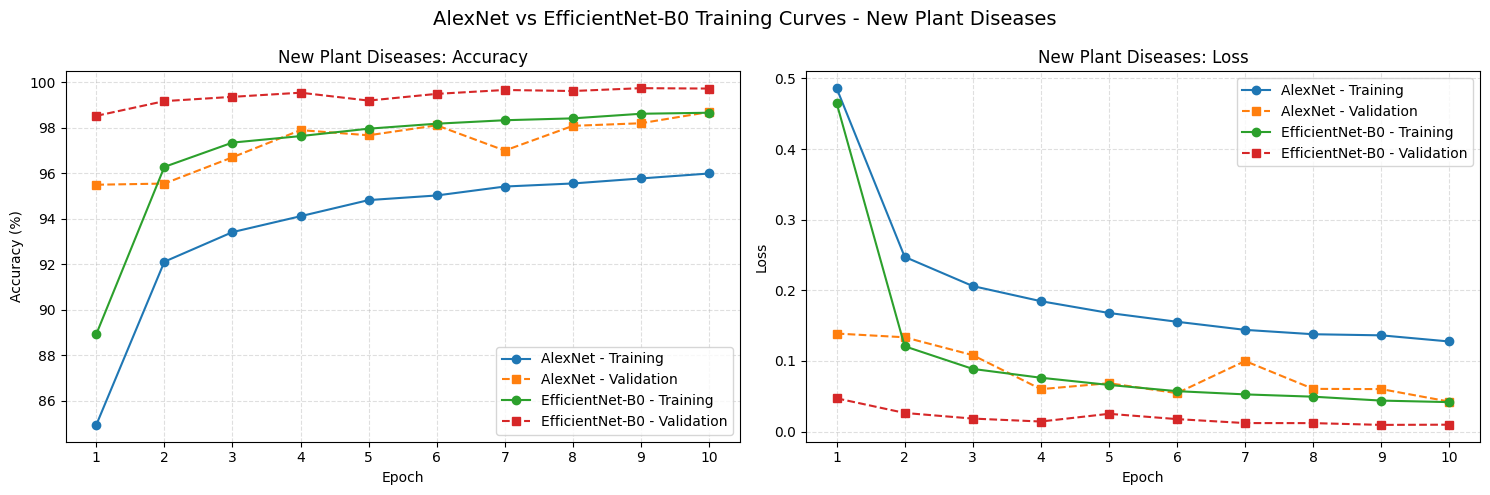

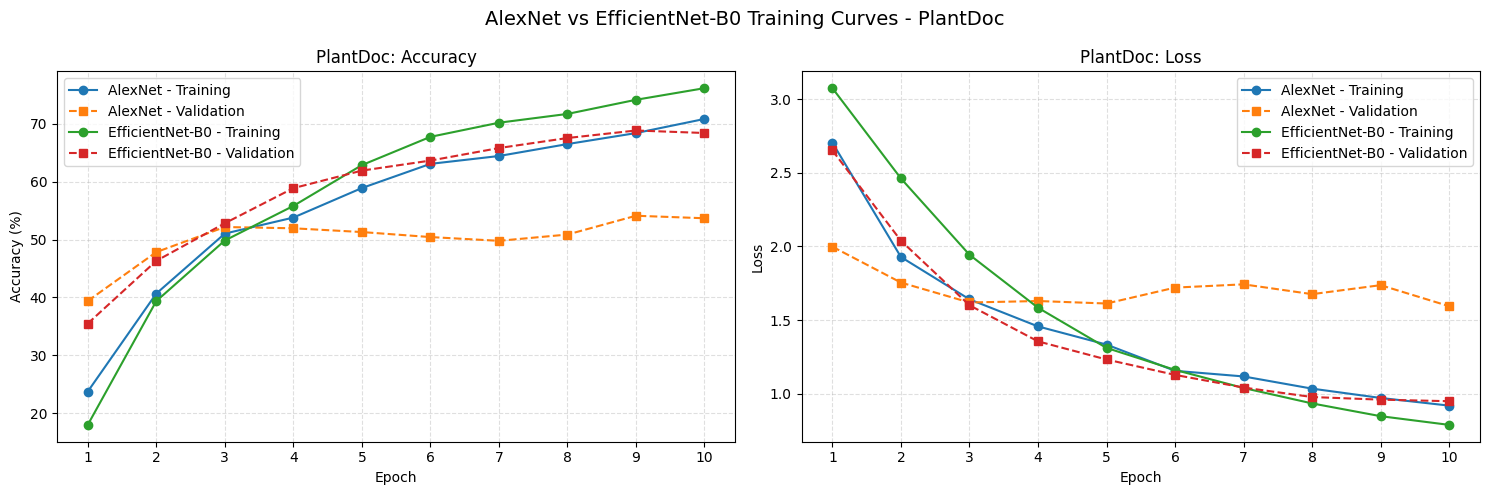

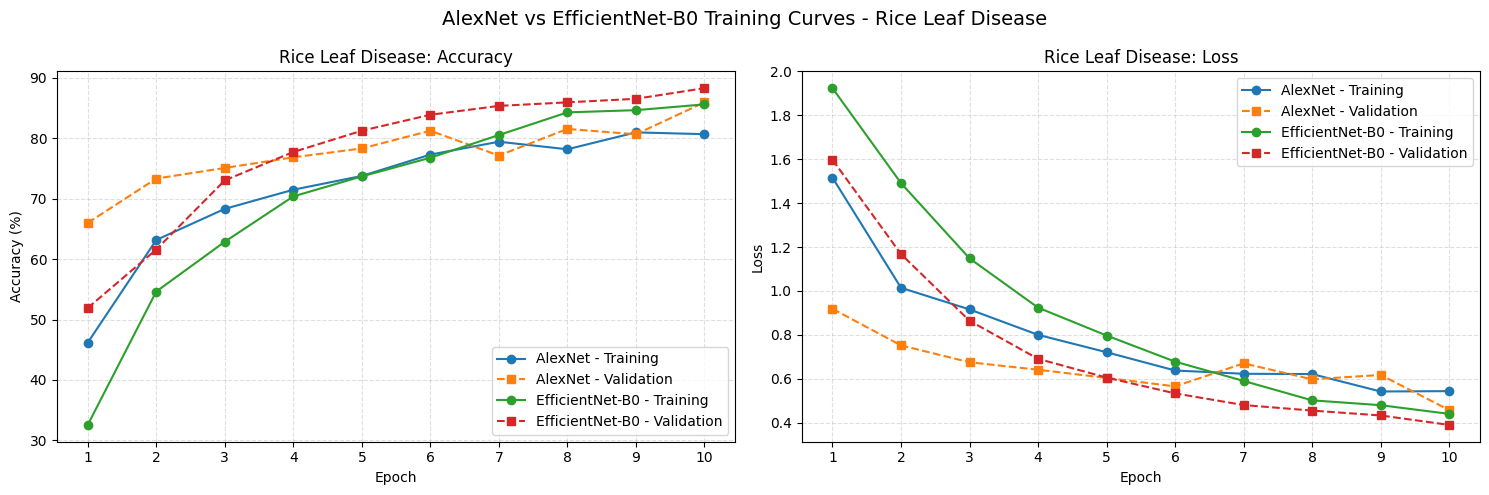

All six experiment histories plotted.
Training curve figures saved in: /kaggle/working/final_project_results


In [59]:

import os
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = "/kaggle/working/final_project_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# All six experiment histories
experiments = {
    "New Plant Diseases": {
        "AlexNet": history,
        "EfficientNet-B0": history_eff
    },
    "PlantDoc": {
        "AlexNet": history_plant_alex,
        "EfficientNet-B0": history_plant_eff
    },
    "Rice Leaf Disease": {
        "AlexNet": rice_alex_history,
        "EfficientNet-B0": rice_eff_history
    }
}

def get_history_values(history_dict, metric):
    """Support both accuracy key naming conventions."""
    if metric == "accuracy":
        train_key = (
            "train_accuracy"
            if "train_accuracy" in history_dict
            else "train_acc"
        )
        val_key = (
            "val_accuracy"
            if "val_accuracy" in history_dict
            else "val_acc"
        )
    else:
        train_key = "train_loss"
        val_key = "val_loss"

    return (
        history_dict[train_key],
        history_dict[val_key]
    )


# Generate one training-curve figure per dataset
for dataset_name, models in experiments.items():

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    epochs = range(1, 11)

    for model_name, hist in models.items():

        train_acc, val_acc = get_history_values(
            hist, "accuracy"
        )

        train_loss, val_loss = get_history_values(
            hist, "loss"
        )

        axes[0].plot(
            epochs, train_acc,
            marker="o",
            label=f"{model_name} - Training"
        )

        axes[0].plot(
            epochs, val_acc,
            marker="s",
            linestyle="--",
            label=f"{model_name} - Validation"
        )

        axes[1].plot(
            epochs, train_loss,
            marker="o",
            label=f"{model_name} - Training"
        )

        axes[1].plot(
            epochs, val_loss,
            marker="s",
            linestyle="--",
            label=f"{model_name} - Validation"
        )

    axes[0].set_title(f"{dataset_name}: Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_xticks(list(epochs))
    axes[0].grid(True, linestyle="--", alpha=0.4)
    axes[0].legend()

    axes[1].set_title(f"{dataset_name}: Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].set_xticks(list(epochs))
    axes[1].grid(True, linestyle="--", alpha=0.4)
    axes[1].legend()

    fig.suptitle(
        f"AlexNet vs EfficientNet-B0 Training Curves - {dataset_name}",
        fontsize=14
    )

    plt.tight_layout()

    filename = (
        dataset_name.lower().replace(" ", "_")
        + "_training_curves.png"
    )

    fig.savefig(
        os.path.join(RESULTS_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("All six experiment histories plotted.")
print("Training curve figures saved in:", RESULTS_DIR)


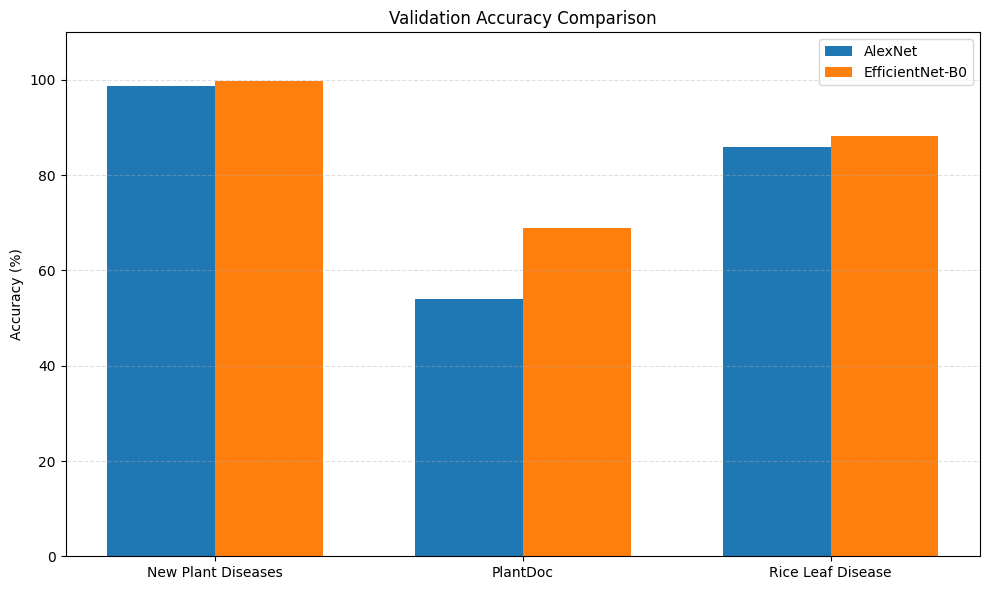

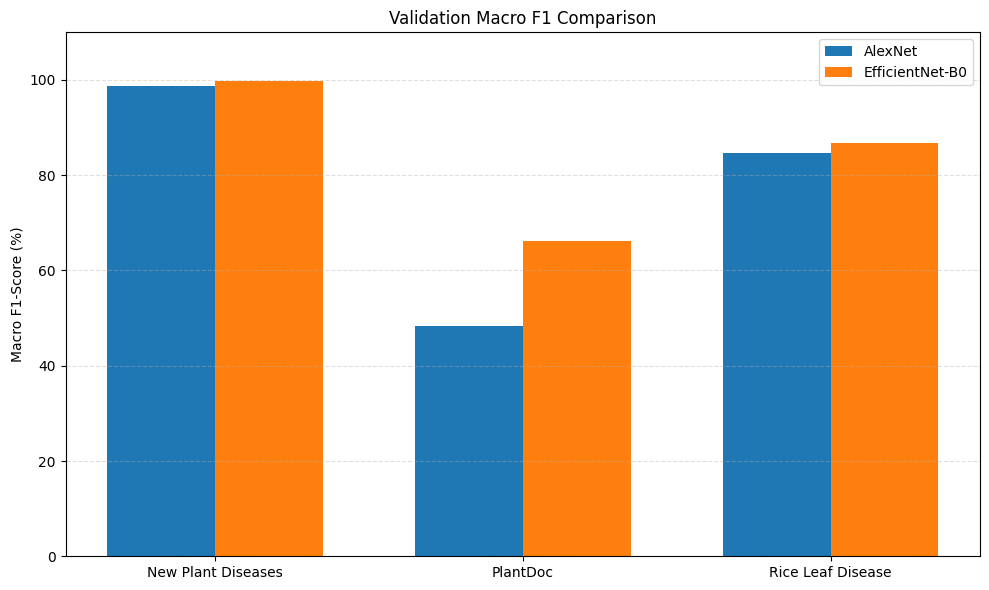

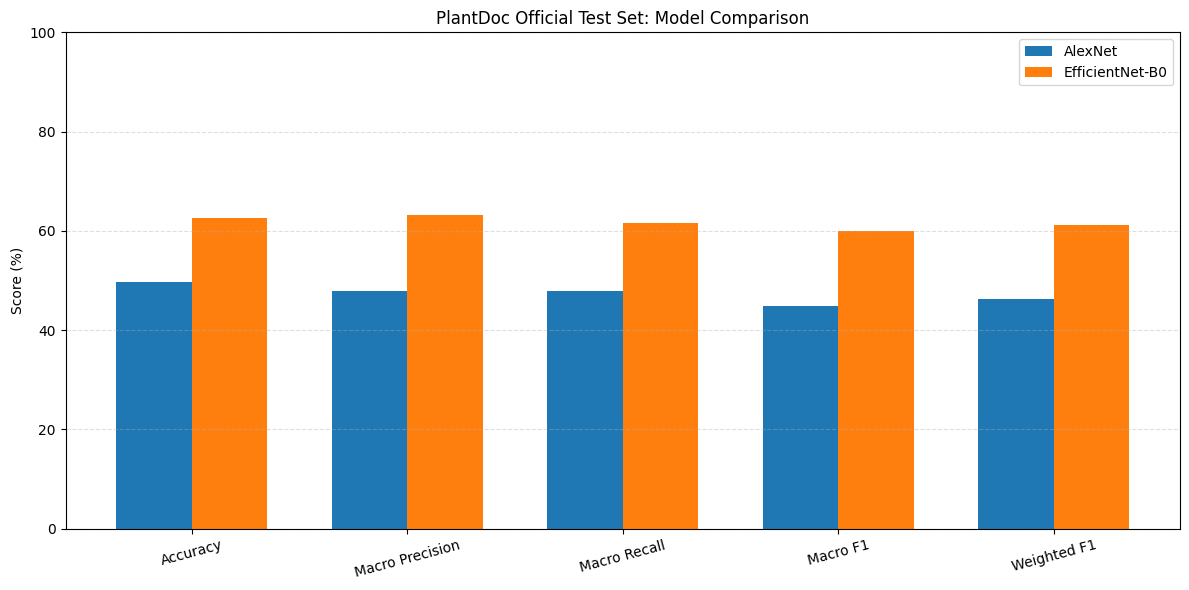

Final comparison figures generated successfully.


In [60]:

import matplotlib.pyplot as plt
import numpy as np
import os

RESULTS_DIR = "/kaggle/working/final_project_results"

datasets = [
    "New Plant Diseases",
    "PlantDoc",
    "Rice Leaf Disease"
]

alexnet_acc = [98.70, 54.11, 85.92]
efficientnet_acc = [99.74, 68.83, 88.27]

alexnet_f1 = [98.68, 48.44, 84.66]
efficientnet_f1 = [99.74, 66.19, 86.68]

x = np.arange(len(datasets))
width = 0.35

# 1. Validation accuracy
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(x - width/2, alexnet_acc, width, label="AlexNet")
ax.bar(x + width/2, efficientnet_acc, width,
       label="EfficientNet-B0")

ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Validation Accuracy Comparison")
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "validation_accuracy_comparison.png"),
    dpi=300
)
plt.show()
plt.close(fig)

# 2. Validation macro F1
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(x - width/2, alexnet_f1, width, label="AlexNet")
ax.bar(x + width/2, efficientnet_f1, width,
       label="EfficientNet-B0")

ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel("Macro F1-Score (%)")
ax.set_title("Validation Macro F1 Comparison")
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "validation_macro_f1_comparison.png"),
    dpi=300
)
plt.show()
plt.close(fig)

# 3. Official PlantDoc test comparison
test_metrics = {
    "Accuracy": [49.79, 62.66],
    "Macro Precision": [47.93, 63.19],
    "Macro Recall": [47.97, 61.58],
    "Macro F1": [44.85, 59.93],
    "Weighted F1": [46.32, 61.11]
}

metric_names = list(test_metrics.keys())
alex_values = [test_metrics[m][0] for m in metric_names]
eff_values = [test_metrics[m][1] for m in metric_names]

x_test = np.arange(len(metric_names))

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x_test - width/2, alex_values, width, label="AlexNet")
ax.bar(x_test + width/2, eff_values, width,
       label="EfficientNet-B0")

ax.set_xticks(x_test)
ax.set_xticklabels(metric_names, rotation=15)
ax.set_ylabel("Score (%)")
ax.set_title("PlantDoc Official Test Set: Model Comparison")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "plantdoc_official_test_comparison.png"),
    dpi=300
)
plt.show()
plt.close(fig)

print("Final comparison figures generated successfully.")





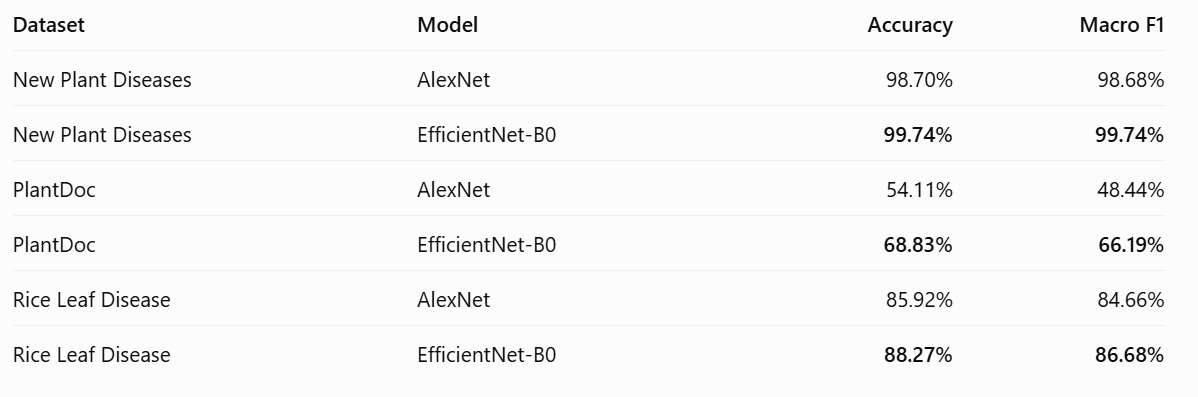